In [ ]:
#@title 1. Check the runtime
import subprocess, sys

print(subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version",
                      "--format=csv,noheader"], capture_output=True, text=True).stdout or
      "No GPU detected -- set Runtime > Change runtime type > GPU before continuing.")
print(f"Python {sys.version.split()[0]}")

import shutil
free_gb = shutil.disk_usage("/content").free / 1e9
print(f"Free disk: {free_gb:.1f} GB")
if free_gb < 25:
    print("WARNING: model weights plus the corpus need ~25GB. Free some space first.")

NVIDIA A100-SXM4-40GB, 40960 MiB, 580.82.07

Python 3.13.15
Free disk: 202.3 GB


In [ ]:
#@title 2. Install dependencies (~3 min)
# datasets<3 on purpose: FEVER is a script-based dataset and datasets 3.0 removed
# script loading entirely. If you switch to a parquet mirror you can drop the pin.
PKGS = "transformers>=4.44 accelerate>=0.33 sentence-transformers>=3.0 'datasets>=2.20,<3.0' faiss-cpu bitsandbytes scipy matplotlib"
!pip install -q -U {PKGS}
print("done -- if pip asks you to restart the runtime, do it, then continue from cell 3 (the config).")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.3.0 requires fsspec==2025.3.0, but you have fsspec 2024.6.1 which is incompatible.
done -- if pip asks you to restart the runtime, do it, then continue from cell 3 (the config).


## Configuration

The defaults are sized for a first pass on an L4. Read the comments before changing them —
a few of these knobs are the difference between a defensible pilot and a misleading one.

In [ ]:
#@title 3. Configuration
CONFIG = {
    # ---- model ----------------------------------------------------------
    # Qwen2.5-7B-Instruct is ungated (no HF token needed). For Llama-3 you must
    # accept the licence on the Hub and set hf_token below.
    "generator": "Qwen/Qwen2.5-7B-Instruct",
    #   alternatives: "mistralai/Mistral-7B-Instruct-v0.3"
    #                 "meta-llama/Meta-Llama-3-8B-Instruct"   (gated)
    "load_in_4bit": True,          # False needs ~16GB VRAM for a 7B in bf16
    "max_new_tokens": 256,
    "batch_size": 4,               # lower this first if you hit OOM
    "hf_token": None,              # only needed for gated models

    "embedder": "sentence-transformers/all-mpnet-base-v2",
    "nli": "microsoft/deberta-large-mnli",

    # ---- scale ----------------------------------------------------------
    "datasets": ["truthfulqa", "halueval", "fever"],
    "n_examples": 100,             # per dataset, BEFORE the dev/test split
    "dev_fraction": 0.2,           # dev is used ONLY for threshold calibration
    "n_distractor_pages": 20000,   # retrieval pool difficulty -- report this number
    "chunk_words": 100,
    "chunk_stride": 80,

    # ---- retrieval ------------------------------------------------------
    "top_k": 5,
    "claim_top_k": 3,
    "use_mmr": True,
    "mmr_lambda": 0.7,

    # ---- framework (tau values are PLACEHOLDERS; cell 10 calibrates them) --
    "tau_support": 0.35,
    "tau_refute": -0.35,
    "max_iterations": 3,
    "acceptance_margin": 0.02,
    "max_claims": 12,

    # ---- experiment -----------------------------------------------------
    "seed": 42,
    "run_ablations": True,         # adds ~45min-2h; set False for a first pass
    "ablation_dataset": "truthfulqa",
    "bootstrap_samples": 10000,
    "alpha": 0.05,
    "use_drive": False,            # True = checkpoint to Google Drive, survives disconnects

    # Hub dataset ids and split names. These move. Cell 6 verifies them and tells
    # you exactly what to change if one fails.
    "dataset_ids": {"truthfulqa": "truthfulqa/truthful_qa",
                    "halueval": "pminervini/HaluEval",
                    "fever": "fever/fever"},   # bare "fever" is rejected: needs namespace/name
    "dataset_splits": {"truthfulqa": "validation", "halueval": "data",
                       "fever": "labelled_dev"},

    # Corpus source. "fever_wiki" is the correct one: FEVER's own wiki dump, so
    # gold evidence pages are findable and evidence recall is meaningful.
    # "wikipedia" is a parquet fallback for when the FEVER script will not load --
    # it runs, but its titles do not align with FEVER evidence ids, so evidence
    # recall goes to ~0. Use it to unblock yourself, not to report numbers.
    "corpus_source": "fever_wiki",
    "wiki_split": "wikipedia_pages",
    "wikipedia_id": "wikimedia/wikipedia",
    "max_wiki_scan": 3000000,
}

for k, v in CONFIG.items():
    print(f"{k:22s} {v}")

generator              Qwen/Qwen2.5-7B-Instruct
load_in_4bit           True
max_new_tokens         256
batch_size             4
hf_token               None
embedder               sentence-transformers/all-mpnet-base-v2
nli                    microsoft/deberta-large-mnli
datasets               ['truthfulqa', 'halueval', 'fever']
n_examples             100
dev_fraction           0.2
n_distractor_pages     20000
chunk_words            100
chunk_stride           80
top_k                  5
claim_top_k            3
use_mmr                True
mmr_lambda             0.7
tau_support            0.35
tau_refute             -0.35
max_iterations         3
acceptance_margin      0.02
max_claims             12
seed                   42
run_ablations          True
ablation_dataset       truthfulqa
bootstrap_samples      10000
alpha                  0.05
use_drive              False
dataset_ids            {'truthfulqa': 'truthfulqa/truthful_qa', 'halueval': 'pminervini/HaluEval', 'fever': 'fever/feve

## 4. Write the library to disk

One long cell. `%%writefile` must be the first line of a cell, so the usual `#@title` header lives here instead.

In [ ]:
%%writefile selfcorrect_lib.py
"""
selfcorrect_lib.py -- condensed single-module implementation of the
self-correcting hallucination-detection framework, for single-session Colab use.

This is a faithful but compressed version of the full repository: same method,
same metrics, same statistics, fewer abstraction layers. Where the full repo
splits a concern across files, this module keeps it in one place.

Nothing here fabricates a number. Every metric is computed from predictions
produced by an actual model run in this session.
"""

from __future__ import annotations

import gc
import hashlib
import json
import re
import time
from dataclasses import dataclass, field, asdict
from pathlib import Path
from typing import Any, Dict, List, Optional, Sequence, Tuple

import numpy as np

# ======================================================================
# 1. Data
# ======================================================================

TASK_GENERATION, TASK_DETECTION, TASK_VERIFICATION = "generation", "detection", "verification"
FEVER_LABELS = ("SUPPORTS", "REFUTES", "NOT ENOUGH INFO")
_FEVER_ALIASES = {"supports": "SUPPORTS", "refutes": "REFUTES",
                  "not enough info": "NOT ENOUGH INFO", "not_enough_info": "NOT ENOUGH INFO",
                  "nei": "NOT ENOUGH INFO"}


@dataclass
class Example:
    uid: str
    dataset: str
    task: str
    question: str
    correct_answers: List[str] = field(default_factory=list)
    incorrect_answers: List[str] = field(default_factory=list)
    best_answer: Optional[str] = None
    candidate_answer: Optional[str] = None
    is_hallucinated: Optional[bool] = None
    knowledge: Optional[str] = None
    claim: Optional[str] = None
    label: Optional[str] = None
    gold_evidence: List[str] = field(default_factory=list)
    meta: Dict[str, Any] = field(default_factory=dict)

    def to_dict(self):
        return asdict(self)


def _uid(ds: str, i: int, text: str) -> str:
    return f"{ds}-{i:05d}-{hashlib.sha1(text.encode()).hexdigest()[:8]}"


def _norm_fever(raw) -> Optional[str]:
    if raw is None:
        return None
    if isinstance(raw, int):
        return FEVER_LABELS[raw] if 0 <= raw < 3 else None
    k = str(raw).strip().lower()
    return _FEVER_ALIASES.get(k, str(raw).strip().upper() or None)


def hf_load(ds_id: str, config: Optional[str], split: str, streaming: bool = False):
    """load_dataset with the two failure modes that actually bite in Colab.

    1. datasets>=2.16 requires trust_remote_code=True for script-based datasets
       (FEVER is one); datasets>=3.0 dropped script support entirely.
    2. Split names differ between mirrors of the same benchmark.
    Both produce an unhelpful traceback, so we retry and then report clearly.
    """
    from datasets import load_dataset, get_dataset_split_names

    args = (ds_id, config) if config else (ds_id,)
    for kw in ({"trust_remote_code": True}, {}):
        try:
            return load_dataset(*args, split=split, streaming=streaming, **kw)
        except TypeError:
            continue          # older/newer datasets without the kwarg
        except ValueError as e:
            if "split" not in str(e).lower():
                raise
            try:
                avail = get_dataset_split_names(ds_id, config)
            except Exception:
                avail = []
            raise ValueError(
                f"Split {split!r} not found for {ds_id} (config={config}). "
                f"Available: {avail}. Fix the split name in CONFIG.") from e
    raise RuntimeError(
        f"Could not load {ds_id} (config={config}). If this is a script-based dataset "
        f"and you are on datasets>=3.0, script loading was removed -- either pin "
        f"datasets<3.0 or point CONFIG['dataset_ids'] at a parquet mirror.")


def load_examples(name: str, ids: Dict[str, str], n: Optional[int], seed: int = 42,
                  splits: Optional[Dict[str, str]] = None) -> List[Example]:
    """Load and normalise one benchmark. Hub ids and split names come from the
    config so a moved dataset can be fixed without touching this code."""
    import random

    splits = splits or {}

    out: List[Example] = []
    if name == "truthfulqa":
        ds = hf_load(ids["truthfulqa"], "generation", splits.get("truthfulqa", "validation"))
        for i, r in enumerate(ds):
            cor = list(r.get("correct_answers") or [])
            best = r.get("best_answer")
            if best and best not in cor:
                cor = [best] + cor
            out.append(Example(_uid("truthfulqa", i, r["question"]), "truthfulqa", TASK_GENERATION,
                               r["question"], correct_answers=cor,
                               incorrect_answers=list(r.get("incorrect_answers") or []),
                               best_answer=best, meta={"category": r.get("category")}))
    elif name == "halueval":
        ds = hf_load(ids["halueval"], "qa", splits.get("halueval", "data"))
        for i, r in enumerate(ds):
            q = r.get("question") or ""
            kn = r.get("knowledge")
            for tag, ans, flag in (("pos", r.get("right_answer"), False),
                                   ("neg", r.get("hallucinated_answer"), True)):
                if not ans:
                    continue
                out.append(Example(_uid("halueval", i, q + tag), "halueval", TASK_DETECTION, q,
                                   candidate_answer=ans, is_hallucinated=flag, knowledge=kn,
                                   meta={"pair_id": i, "polarity": tag}))
    elif name == "fever":
        ds = hf_load(ids["fever"], "v1.0", splits.get("fever", "labelled_dev"))
        for i, r in enumerate(ds):
            claim = r.get("claim", "")
            gold = []
            page = r.get("evidence_wiki_url")
            if page:
                gold.append(str(page))
            ev = r.get("evidence")
            if isinstance(ev, list):
                for e in ev:
                    if isinstance(e, dict) and (e.get("evidence_wiki_url") or e.get("page")):
                        gold.append(str(e.get("evidence_wiki_url") or e.get("page")))
            out.append(Example(_uid("fever", i, claim), "fever", TASK_VERIFICATION,
                               f"Is the following claim true? {claim}", claim=claim,
                               label=_norm_fever(r.get("label")),
                               gold_evidence=sorted({g for g in gold if g})))
    else:
        raise ValueError(name)

    if n is not None and n < len(out):
        if name == "halueval":
            # Sample by pair so the pos/neg balance is preserved exactly.
            pairs = sorted({e.meta["pair_id"] for e in out})
            keep = set(random.Random(seed).sample(pairs, max(1, n // 2)))
            out = [e for e in out if e.meta["pair_id"] in keep]
        else:
            out = random.Random(seed).sample(out, n)
        out.sort(key=lambda e: e.uid)
    return out


def dev_test_split(examples: List[Example], frac: float, seed: int = 42):
    """Hash-keyed split: adding examples later never reshuffles the existing
    assignment, so a dev-calibrated threshold stays valid."""
    dev, test = [], []
    for e in examples:
        b = int(hashlib.sha1(f"{seed}:{e.uid}".encode()).hexdigest()[:8], 16) / 0xFFFFFFFF
        (dev if b < frac else test).append(e)
    return dev, test


# ======================================================================
# 2. Corpus + retrieval
# ======================================================================

_MARKUP = re.compile(r"-LRB-|-RRB-|-LSB-|-RSB-|-COLON-")
_WS = re.compile(r"\s+")


def clean(t: str) -> str:
    return _WS.sub(" ", _MARKUP.sub(" ", t or "")).strip()


def chunk(text: str, size: int, stride: int) -> List[str]:
    w = text.split()
    if not w:
        return []
    if len(w) <= size:
        return [" ".join(w)]
    out = []
    for s in range(0, len(w), max(1, stride)):
        win = w[s:s + size]
        if len(win) < size // 4 and out:
            break
        out.append(" ".join(win))
        if s + size >= len(w):
            break
    return out


def build_corpus(examples_by_ds: Dict[str, List[Example]], wiki_id: str,
                 distractor_pages: int, chunk_words: int, chunk_stride: int,
                 source: str = "fever_wiki", wiki_split: str = "wikipedia_pages",
                 max_scan: int = 3_000_000, log=print) -> List[Dict[str, Any]]:
    """Build a reduced retrieval pool.

    Colab cannot embed the full 5.4M-page FEVER dump in one session, so the pool
    is: every gold-evidence page for the sampled FEVER claims, plus N randomly
    streamed distractor pages, plus the HaluEval knowledge passages.

    This is a REDUCED POOL, not full-wiki retrieval. It makes retrieval easier
    than the standard setting and must be disclosed as such in the paper. The
    distractor count is the knob that controls how much easier.
    """
    wanted = set()
    for ex in examples_by_ds.get("fever", []):
        wanted.update(ex.gold_evidence)
    log(f"  gold evidence pages required: {len(wanted)}")

    docs: List[Dict[str, str]] = []
    seen_titles = set()
    if source == "fever_wiki":
        stream = hf_load(wiki_id, "wiki_pages", wiki_split, streaming=True)
        title_key, text_key = "id", "text"
    elif source == "wikipedia":
        # Parquet fallback: always loadable, but its page titles do not align with
        # FEVER's evidence ids, so FEVER evidence recall will be near zero. Use it
        # only to get the pipeline running, and say so if you report anything.
        stream = hf_load(wiki_id, None, "train", streaming=True)
        title_key, text_key = "title", "text"
    else:
        raise ValueError(f"unknown corpus source {source!r}")
    n_dist = 0
    for i, row in enumerate(stream):
        if i >= max_scan:
            log(f"  hit max_scan={max_scan}; stopping with {len(wanted)} gold pages unfound")
            break
        title = row.get(title_key)
        if not title or title in seen_titles:
            continue
        is_gold = title in wanted
        if is_gold:
            wanted.discard(title)
        elif n_dist < distractor_pages:
            n_dist += 1
        else:
            if not wanted:
                break
            continue
        seen_titles.add(title)
        docs.append({"title": title, "text": row.get(text_key, "")})
        if i % 200000 == 0 and i:
            log(f"  streamed {i} pages, kept {len(docs)}, {len(wanted)} gold still missing")
        if not wanted and n_dist >= distractor_pages:
            break
    if wanted:
        log(f"  WARNING: {len(wanted)} gold pages never found in the stream; "
            f"FEVER evidence recall is capped below 100% for those claims.")

    for ex in examples_by_ds.get("halueval", []):
        if ex.knowledge:
            docs.append({"title": f"halueval::{ex.meta.get('pair_id')}", "text": ex.knowledge})

    passages = []
    for d in docs:
        raw_title = str(d["title"])
        body = clean(d["text"])
        if not body:
            continue
        # pid keeps the RAW title: FEVER gold evidence is matched on the raw wiki
        # id, so cleaning it here would silently zero out evidence recall.
        for j, c in enumerate(chunk(body, chunk_words, chunk_stride)):
            passages.append({"pid": f"{raw_title}::{j}", "title": clean(raw_title) or None, "text": c})
    log(f"  {len(docs)} documents -> {len(passages)} passages")
    return passages


@dataclass
class Passage:
    pid: str
    text: str
    title: Optional[str] = None
    score: float = 0.0

    def cite(self):
        return f"[{self.title}] {self.text}" if self.title else self.text

    def to_dict(self):
        return {"pid": self.pid, "title": self.title, "text": self.text, "score": round(self.score, 4)}


class Retriever:
    """FAISS inner-product retrieval with optional MMR diversification."""

    def __init__(self, index, passages, embedder, top_k=5, claim_top_k=3,
                 use_mmr=True, mmr_lambda=0.7):
        self.index, self.passages, self.embedder = index, passages, embedder
        self.top_k, self.claim_top_k = top_k, claim_top_k
        self.use_mmr, self.mmr_lambda = use_mmr, mmr_lambda

    def retrieve(self, q: str, top_k=None) -> List[Passage]:
        return self.retrieve_batch([q], top_k)[0]

    def retrieve_batch(self, queries: Sequence[str], top_k=None) -> List[List[Passage]]:
        import faiss
        if not queries:
            return []
        k = top_k or self.top_k
        fetch = min(k * 3 if self.use_mmr else k, len(self.passages))
        qv = np.ascontiguousarray(self.embedder.encode(list(queries)).astype("float32"))
        faiss.normalize_L2(qv)
        scores, idxs = self.index.search(qv, fetch)
        out = []
        for qi in range(len(queries)):
            cands = []
            for s, p in zip(scores[qi], idxs[qi]):
                if p < 0:
                    continue
                r = self.passages[int(p)]
                cands.append(Passage(str(r["pid"]), r["text"], r.get("title"), float(s)))
            if self.use_mmr and len(cands) > k:
                cands = self._mmr(qv[qi], cands, k)
            out.append(cands[:k])
        return out

    def _mmr(self, qvec, cands, k):
        """Near-duplicate passages make the NLI aggregate falsely confident;
        MMR is the cheap guard against that."""
        v = self.embedder.encode([c.text for c in cands])
        v /= np.clip(np.linalg.norm(v, axis=1, keepdims=True), 1e-8, None)
        qv = qvec / max(float(np.linalg.norm(qvec)), 1e-8)
        rel = v @ qv
        sel, rem = [], list(range(len(cands)))
        while rem and len(sel) < k:
            if not sel:
                pick = int(max(rem, key=lambda i: rel[i]))
            else:
                pen = (v[rem] @ v[sel].T).max(axis=1)
                pick = rem[int(np.argmax(self.mmr_lambda * rel[rem] - (1 - self.mmr_lambda) * pen))]
            sel.append(pick)
            rem.remove(pick)
        return [cands[i] for i in sel]


def format_evidence(ps: Sequence[Passage], max_chars=3000) -> str:
    lines, tot = [], 0
    for i, p in enumerate(ps, 1):
        ln = f"[{i}] {p.cite()}"
        if tot + len(ln) > max_chars:
            break
        lines.append(ln)
        tot += len(ln)
    return "\n".join(lines) if lines else "(no evidence retrieved)"


# ======================================================================
# 3. Models
# ======================================================================

@dataclass
class GenResult:
    text: str
    prompt_tokens: int = 0
    completion_tokens: int = 0


class Generator:
    """HF causal LM using the checkpoint's own chat template, so the same code
    runs on Llama-3, Qwen2.5 and Mistral without prompt surgery."""

    def __init__(self, name, load_in_4bit=True, dtype="bfloat16",
                 max_new_tokens=256, batch_size=8, hf_token=None):
        import torch
        from transformers import AutoModelForCausalLM, AutoTokenizer

        self.torch, self.name = torch, name
        self.max_new_tokens, self.batch_size = max_new_tokens, batch_size
        self.tok = AutoTokenizer.from_pretrained(name, token=hf_token)
        if self.tok.pad_token is None:
            self.tok.pad_token = self.tok.eos_token
        self.tok.padding_side = "left"  # required for batched decoder-only generation

        kw = {"device_map": "auto", "token": hf_token}
        if load_in_4bit:
            from transformers import BitsAndBytesConfig
            kw["quantization_config"] = BitsAndBytesConfig(
                load_in_4bit=True, bnb_4bit_compute_dtype=getattr(torch, dtype),
                bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True)
        # transformers renamed torch_dtype -> dtype; support both.
        try:
            self.model = AutoModelForCausalLM.from_pretrained(
                name, dtype=getattr(torch, dtype), **kw).eval()
        except TypeError:
            self.model = AutoModelForCausalLM.from_pretrained(
                name, torch_dtype=getattr(torch, dtype), **kw).eval()
        self.device = next(self.model.parameters()).device

    def _render(self, msgs):
        if getattr(self.tok, "chat_template", None):
            return self.tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
        return "\n\n".join(f"{m['role'].upper()}: {m['content']}" for m in msgs) + "\n\nASSISTANT:"

    def chat(self, msgs, max_new_tokens=None) -> GenResult:
        return self.chat_batch([msgs], max_new_tokens)[0]

    def chat_batch(self, batch, max_new_tokens=None) -> List[GenResult]:
        torch, out = self.torch, []
        for s in range(0, len(batch), self.batch_size):
            chunk_ = batch[s:s + self.batch_size]
            enc = self.tok([self._render(m) for m in chunk_], return_tensors="pt",
                           padding=True, add_special_tokens=False).to(self.device)
            with torch.inference_mode():
                gen = self.model.generate(
                    **enc, max_new_tokens=max_new_tokens or self.max_new_tokens,
                    do_sample=False, pad_token_id=self.tok.pad_token_id)
            in_len = enc["input_ids"].shape[1]
            for i in range(len(chunk_)):
                ids = gen[i][in_len:]
                out.append(GenResult(self.tok.decode(ids, skip_special_tokens=True).strip(),
                                     int(enc["attention_mask"][i].sum()),
                                     int((ids != self.tok.pad_token_id).sum())))
        return out

    def free(self):
        del self.model
        gc.collect()
        self.torch.cuda.empty_cache()


@dataclass
class NLIScore:
    entail: float
    neutral: float
    contradict: float


class NLI:
    def __init__(self, name, batch_size=32, max_length=512):
        import torch
        from transformers import AutoModelForSequenceClassification, AutoTokenizer

        self.torch, self.bs, self.max_length = torch, batch_size, max_length
        self.tok = AutoTokenizer.from_pretrained(name)
        self.model = AutoModelForSequenceClassification.from_pretrained(name).eval()
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        self.model.to(self.device)
        # Resolve label indices from the checkpoint. deberta-large-mnli and
        # roberta-large-mnli disagree on ordering; assuming one silently
        # inverts every verdict.
        l2i = {str(v).upper(): int(k) for k, v in self.model.config.id2label.items()}
        missing = {"ENTAILMENT", "NEUTRAL", "CONTRADICTION"} - set(l2i)
        if missing:
            raise ValueError(f"NLI checkpoint {name} labels={sorted(l2i)}, missing {missing}")
        self.ie, self.inu, self.ic = l2i["ENTAILMENT"], l2i["NEUTRAL"], l2i["CONTRADICTION"]

    def score_pairs(self, pairs) -> List[NLIScore]:
        torch, out = self.torch, []
        for s in range(0, len(pairs), self.bs):
            ch = list(pairs[s:s + self.bs])
            enc = self.tok([p for p, _ in ch], [h for _, h in ch], return_tensors="pt",
                           padding=True, truncation=True, max_length=self.max_length).to(self.device)
            with torch.inference_mode():
                pr = torch.softmax(self.model(**enc).logits, -1).cpu().numpy()
            out += [NLIScore(float(r[self.ie]), float(r[self.inu]), float(r[self.ic])) for r in pr]
        return out

    def support_score(self, claim: str, evidence: Sequence[str]) -> Tuple[float, List[NLIScore]]:
        """s(claim) = max entailment - max contradiction.

        Asymmetric max rather than a mean: averaging lets a large pool of
        irrelevant neutral passages wash out one decisive contradiction.
        """
        if not evidence:
            return 0.0, []
        sc = self.score_pairs([(e, claim) for e in evidence])
        return float(max(s.entail for s in sc) - max(s.contradict for s in sc)), sc

    def free(self):
        del self.model
        gc.collect()
        self.torch.cuda.empty_cache()


# ======================================================================
# 4. Verification
# ======================================================================

SUPPORTED, REFUTED, UNVERIFIED = "SUPPORTED", "REFUTED", "NOT ENOUGH INFO"

DECOMPOSE_SYS = ("You break text into atomic factual claims. An atomic claim states exactly one "
                 "fact, is self-contained, and is verifiable against an encyclopaedia. Ignore "
                 "opinions, hedges and meta-commentary.")
DECOMPOSE_USR = """Break the answer below into atomic factual claims.

Rules:
- Resolve every pronoun using the question and answer.
- One fact per claim. Split conjunctions.
- Do not add facts.
- If there is no verifiable factual content, return [].
- Output ONLY a JSON array of strings.

Question: {q}
Answer: {a}

JSON array:"""

_SENT = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9])")
_NUM = re.compile(r"^\s*(?:\d+[.)]|[-*])\s+(.*)$")


def parse_claim_list(raw: str) -> Optional[List[str]]:
    """Instruction-tuned models leak prose around JSON, so parse defensively:
    strict JSON, then bracket extraction, then numbered lines."""
    t = raw.strip()
    if t.startswith("```"):
        t = re.sub(r"^```[a-zA-Z]*\n?", "", t)
        t = re.sub(r"\n?```$", "", t).strip()
    for cand in (t, t[t.find("["):t.rfind("]") + 1] if 0 <= t.find("[") < t.rfind("]") else ""):
        if not cand:
            continue
        try:
            o = json.loads(cand)
            if isinstance(o, list):
                return [str(x).strip() for x in o if str(x).strip()]
        except json.JSONDecodeError:
            pass
    lines = [m.group(1).strip().strip('",') for m in (_NUM.match(l) for l in t.splitlines()) if m]
    return [l for l in lines if l] or None


def extract_claims(gen: Generator, question: str, answer: str,
                   max_claims=12, enabled=True) -> List[str]:
    answer = (answer or "").strip()
    if not answer:
        return []
    if not enabled:
        return [answer]  # no-decomposition ablation arm
    txt = gen.chat([{"role": "system", "content": DECOMPOSE_SYS},
                    {"role": "user", "content": DECOMPOSE_USR.format(q=question, a=answer)}],
                   max_new_tokens=384).text
    claims = parse_claim_list(txt) or [s.strip() for s in _SENT.split(answer) if len(s.strip()) > 3]
    seen, out = set(), []
    for c in claims:
        k = c.lower().strip(" .")
        if k and k not in seen:
            seen.add(k)
            out.append(c)
        if len(out) >= max_claims:
            break
    return out


@dataclass
class Verdict:
    claim: str
    index: int
    verdict: str
    support: float
    max_entail: float
    max_contradict: float
    evidence: List[Passage] = field(default_factory=list)

    def to_dict(self):
        return {"claim": self.claim, "index": self.index, "verdict": self.verdict,
                "support": round(self.support, 4), "max_entail": round(self.max_entail, 4),
                "max_contradict": round(self.max_contradict, 4),
                "evidence": [p.to_dict() for p in self.evidence]}


@dataclass
class Report:
    verdicts: List[Verdict]
    aggregate_support: float
    n_supported: int
    n_refuted: int
    n_unverified: int

    @property
    def flagged(self):
        return [v for v in self.verdicts if v.verdict != SUPPORTED]

    @property
    def all_supported(self):
        return bool(self.verdicts) and not self.flagged

    def to_dict(self):
        return {"aggregate_support": round(self.aggregate_support, 4),
                "n_supported": self.n_supported, "n_refuted": self.n_refuted,
                "n_unverified": self.n_unverified,
                "verdicts": [v.to_dict() for v in self.verdicts]}


class Verifier:
    def __init__(self, retriever: Retriever, nli: NLI, tau_support=0.35, tau_refute=-0.35,
                 claim_conditioned=True):
        self.r, self.nli = retriever, nli
        self.tau_s, self.tau_r = tau_support, tau_refute
        self.claim_conditioned = claim_conditioned

    def decide(self, s: float) -> str:
        return SUPPORTED if s >= self.tau_s else (REFUTED if s <= self.tau_r else UNVERIFIED)

    def verify(self, claims: Sequence[str], question: str = "",
               shared: Optional[List[Passage]] = None) -> Report:
        if not claims:
            return Report([], 0.0, 0, 0, 0)
        if self.claim_conditioned:
            # The point of the method: a question-level query returns passages
            # about the topic, a claim-level query returns passages about the
            # specific assertion, which is what the NLI model needs.
            qs = [f"{question} {c}".strip() if question else c for c in claims]
            ev_sets = self.r.retrieve_batch(qs, top_k=self.r.claim_top_k)
        else:
            pool = shared if shared is not None else self.r.retrieve(question, self.r.claim_top_k)
            ev_sets = [list(pool) for _ in claims]

        vs = []
        for i, (c, ev) in enumerate(zip(claims, ev_sets)):
            sup, sc = self.nli.support_score(c, [p.cite() for p in ev])
            vs.append(Verdict(c, i, self.decide(sup), sup,
                              max((s.entail for s in sc), default=0.0),
                              max((s.contradict for s in sc), default=0.0), list(ev)))
        return Report(vs, sum(v.support for v in vs) / len(vs),
                      sum(v.verdict == SUPPORTED for v in vs),
                      sum(v.verdict == REFUTED for v in vs),
                      sum(v.verdict == UNVERIFIED for v in vs))


def calibrate_tau(supports: Sequence[float], labels: Sequence[bool]) -> Dict[str, float]:
    """Pick tau by maximising F1 on the hallucinated class. DEV SPLIT ONLY."""
    s, y = np.asarray(supports, float), np.asarray(labels, bool)
    best = {"tau": 0.0, "f1": -1.0, "precision": 0.0, "recall": 0.0}
    for tau in np.linspace(-1, 1, 201):
        pred = s < tau
        tp, fp, fn = int((pred & y).sum()), int((pred & ~y).sum()), int((~pred & y).sum())
        p = tp / (tp + fp) if tp + fp else 0.0
        r = tp / (tp + fn) if tp + fn else 0.0
        f1 = 2 * p * r / (p + r) if p + r else 0.0
        if f1 > best["f1"]:
            best = {"tau": float(tau), "f1": f1, "precision": p, "recall": r}
    return best


REVISE_SYS = ("You are a careful editor. You correct factual errors using only the evidence "
              "provided. You never invent facts. Saying something is unknown is better than guessing.")
REVISE_USR = """A draft answer was fact-checked claim by claim. Some claims failed.

Question: {q}

Draft answer:
{a}

Failed claims and their evidence:
{issues}

Rewrite the answer so that:
1. Claims marked CONTRADICTED are corrected to match the evidence, or removed.
2. Claims marked UNSUPPORTED are grounded, softened to explicit uncertainty, or removed.
3. Claims that passed are kept unchanged.
4. No new factual claims beyond the evidence.
5. Similar length, directly answers the question.

Output only the revised answer."""

_WORD = {REFUTED: "CONTRADICTED", UNVERIFIED: "UNSUPPORTED"}


def revise(gen: Generator, question: str, answer: str, flagged: Sequence[Verdict]) -> GenResult:
    issues = "\n".join(
        f"- Claim: {v.claim}\n  Status: {_WORD.get(v.verdict, v.verdict)} "
        f"(support {v.support:+.2f})\n  Evidence:\n    "
        + format_evidence(v.evidence[:3], 1200).replace("\n", "\n    ") for v in flagged)
    return gen.chat([{"role": "system", "content": REVISE_SYS},
                     {"role": "user", "content": REVISE_USR.format(q=question, a=answer,
                                                                   issues=issues or "(none)")}])


# ======================================================================
# 5. Systems
# ======================================================================

ANSWER_SYS = ("You are a knowledgeable and cautious assistant. Answer factual questions concisely "
              "and accurately. If you do not know, say so rather than guessing.")
GROUNDED_SYS = ("You are a knowledgeable and cautious assistant. Answer using the provided evidence. "
                "If the evidence does not answer the question, say the evidence is insufficient.")
GROUNDED_USR = "Evidence:\n{e}\n\nQuestion: {q}\n\nAnswer using the evidence above."
DETECT_USR = ("Question: {q}\nProposed answer: {a}\n\nDoes the proposed answer contain any factual "
              "claim that is false or unsupported? Reply with exactly one word: YES or NO.")
FEVER_USR = ("Claim: {c}\n\nDecide whether the claim is SUPPORTED, REFUTED, or whether there is NOT "
             "ENOUGH INFO. Reply with exactly one of: SUPPORTS, REFUTES, NOT ENOUGH INFO.")


def parse_yes_no(t: str) -> Optional[bool]:
    t = (t or "").strip().lower()
    if t.startswith("yes"):
        return True
    if t.startswith("no"):
        return False
    if "yes" in t and "no" not in t:
        return True
    if "no" in t and "yes" not in t:
        return False
    return None


def parse_fever(t: str) -> Optional[str]:
    t = (t or "").strip().upper()
    for l in ("NOT ENOUGH INFO", "SUPPORTS", "REFUTES"):
        if l in t:
            return l
    return "SUPPORTS" if t.startswith("SUPPORT") else ("REFUTES" if t.startswith("REFUT") else None)


@dataclass
class Response:
    uid: str
    dataset: str
    system: str
    question: str
    answer: str
    draft_answer: Optional[str] = None
    iterations: int = 0
    revisions_applied: int = 0
    revisions_rejected: int = 0
    predicted_hallucination: Optional[bool] = None
    predicted_label: Optional[str] = None
    confidence: Optional[float] = None
    verification: Optional[Dict] = None
    trace: List[Dict] = field(default_factory=list)
    evidence: List[Dict] = field(default_factory=list)
    llm_calls: int = 0
    retrieval_calls: int = 0
    nli_calls: int = 0
    prompt_tokens: int = 0
    completion_tokens: int = 0
    latency_s: float = 0.0
    error: Optional[str] = None

    def to_dict(self):
        return asdict(self)


class System:
    name = "base"

    def answer(self, ex: Example) -> Response:
        raise NotImplementedError

    def run(self, ex: Example) -> Response:
        """One bad example must not lose a two-hour Colab session, but errors
        are recorded rather than dropped -- the error rate is reported."""
        t0 = time.perf_counter()
        try:
            r = self.answer(ex)
        except Exception as e:
            r = Response(ex.uid, ex.dataset, self.name, ex.question, "",
                         error=f"{type(e).__name__}: {e}")
        r.latency_s = time.perf_counter() - t0
        return r


class VanillaLLM(System):
    name = "vanilla"

    def __init__(self, gen):
        self.gen = gen

    def answer(self, ex):
        if ex.task == TASK_DETECTION:
            usr, mx = DETECT_USR.format(q=ex.question, a=ex.candidate_answer or ""), 8
        elif ex.task == TASK_VERIFICATION:
            usr, mx = FEVER_USR.format(c=ex.claim or ""), 16
        else:
            usr, mx = ex.question, None
        res = self.gen.chat([{"role": "system", "content": ANSWER_SYS},
                             {"role": "user", "content": usr}], max_new_tokens=mx)
        r = Response(ex.uid, ex.dataset, self.name, ex.question, res.text, llm_calls=1,
                     prompt_tokens=res.prompt_tokens, completion_tokens=res.completion_tokens)
        if ex.task == TASK_DETECTION:
            r.predicted_hallucination = parse_yes_no(res.text)
            r.error = None if r.predicted_hallucination is not None else "unparseable_detection"
        elif ex.task == TASK_VERIFICATION:
            r.predicted_label = parse_fever(res.text)
            r.error = None if r.predicted_label else "unparseable_fever_label"
        return r


class RAG(System):
    name = "rag"

    def __init__(self, gen, retriever):
        self.gen, self.r = gen, retriever

    def answer(self, ex):
        ps = self.r.retrieve(ex.claim or ex.question)
        ev = format_evidence(ps)
        if ex.task == TASK_DETECTION:
            usr, mx = f"Evidence:\n{ev}\n\n" + DETECT_USR.format(q=ex.question, a=ex.candidate_answer or ""), 8
        elif ex.task == TASK_VERIFICATION:
            usr, mx = f"Evidence:\n{ev}\n\n" + FEVER_USR.format(c=ex.claim or ""), 16
        else:
            usr, mx = GROUNDED_USR.format(e=ev, q=ex.question), None
        res = self.gen.chat([{"role": "system", "content": GROUNDED_SYS},
                             {"role": "user", "content": usr}], max_new_tokens=mx)
        r = Response(ex.uid, ex.dataset, self.name, ex.question, res.text, llm_calls=1,
                     retrieval_calls=1, prompt_tokens=res.prompt_tokens,
                     completion_tokens=res.completion_tokens,
                     evidence=[p.to_dict() for p in ps])
        if ex.task == TASK_DETECTION:
            r.predicted_hallucination = parse_yes_no(res.text)
            r.error = None if r.predicted_hallucination is not None else "unparseable_detection"
        elif ex.task == TASK_VERIFICATION:
            r.predicted_label = parse_fever(res.text)
            r.error = None if r.predicted_label else "unparseable_fever_label"
        return r


class SelfCorrecting(System):
    """draft -> decompose -> claim-conditioned retrieval -> NLI -> targeted
    revision -> re-verify -> commit only if aggregate support improved."""

    name = "self_correct"

    def __init__(self, gen, retriever, verifier, max_iterations=3, acceptance_margin=0.02,
                 decompose=True, acceptance_gate=True, max_claims=12,
                 revise_only_flagged=True, ground_draft=True, tau_support=0.35):
        self.gen, self.r, self.v = gen, retriever, verifier
        self.max_iterations, self.margin = max_iterations, acceptance_margin
        self.decompose, self.gate = decompose, acceptance_gate
        self.max_claims, self.revise_only_flagged = max_claims, revise_only_flagged
        # ground_draft=True is the fair comparison against RAG: both start from a
        # retrieval-grounded draft, so any gain is attributable to verification
        # and correction rather than to retrieval.
        self.ground_draft, self.tau_support = ground_draft, tau_support

    def _verify_text(self, ex, text, r):
        claims = extract_claims(self.gen, ex.question, text, self.max_claims, self.decompose)
        if self.decompose:
            r.llm_calls += 1
        rep = self.v.verify(claims, ex.question)
        r.retrieval_calls += len(claims) if self.v.claim_conditioned else 1
        r.nli_calls += sum(len(v.evidence) for v in rep.verdicts)
        return rep

    def answer(self, ex):
        if ex.task == TASK_DETECTION:
            return self._detect(ex)
        if ex.task == TASK_VERIFICATION:
            return self._fever(ex)
        return self._generate(ex)

    def _generate(self, ex):
        r = Response(ex.uid, ex.dataset, self.name, ex.question, "")
        if self.ground_draft:
            ps = self.r.retrieve(ex.question)
            r.retrieval_calls += 1
            r.evidence = [p.to_dict() for p in ps]
            msgs = [{"role": "system", "content": GROUNDED_SYS},
                    {"role": "user", "content": GROUNDED_USR.format(e=format_evidence(ps), q=ex.question)}]
        else:
            msgs = [{"role": "system", "content": ANSWER_SYS}, {"role": "user", "content": ex.question}]
        res = self.gen.chat(msgs)
        r.llm_calls += 1
        r.prompt_tokens += res.prompt_tokens
        r.completion_tokens += res.completion_tokens
        cur = res.text
        r.draft_answer = cur

        rep = self._verify_text(ex, cur, r)
        best, best_rep = rep.aggregate_support, rep
        r.trace.append({"iteration": 0, "stage": "draft", "answer": cur,
                        "aggregate_support": round(rep.aggregate_support, 4),
                        "n_flagged": len(rep.flagged)})

        for it in range(1, self.max_iterations + 1):
            if rep.all_supported or not rep.verdicts:
                break
            flagged = rep.flagged if self.revise_only_flagged else rep.verdicts
            res = revise(self.gen, ex.question, cur, flagged)
            r.llm_calls += 1
            r.prompt_tokens += res.prompt_tokens
            r.completion_tokens += res.completion_tokens
            cand = res.text.strip()
            if not cand:
                break
            crep = self._verify_text(ex, cand, r)
            accept = (crep.aggregate_support >= best + self.margin) or not self.gate
            r.trace.append({"iteration": it, "stage": "revision", "answer": cand,
                            "aggregate_support": round(crep.aggregate_support, 4),
                            "delta": round(crep.aggregate_support - best, 4),
                            "n_flagged": len(crep.flagged), "accepted": accept})
            if accept:
                cur, rep = cand, crep
                if crep.aggregate_support > best:
                    best, best_rep = crep.aggregate_support, crep
                r.revisions_applied += 1
                r.iterations = it
            else:
                # Gate closed: further revisions from the same draft explore the
                # same failing region, so stop paying for them.
                r.revisions_rejected += 1
                break

        r.answer = cur
        r.verification = best_rep.to_dict()
        r.confidence = best_rep.aggregate_support
        r.predicted_hallucination = bool(best_rep.flagged)
        return r

    def _detect(self, ex):
        r = Response(ex.uid, ex.dataset, self.name, ex.question, ex.candidate_answer or "")
        rep = self._verify_text(ex, ex.candidate_answer or "", r)
        r.verification, r.confidence = rep.to_dict(), rep.aggregate_support
        r.predicted_hallucination = bool(rep.n_refuted > 0 or rep.aggregate_support < self.tau_support)
        return r

    def _fever(self, ex):
        r = Response(ex.uid, ex.dataset, self.name, ex.question, ex.claim or "")
        rep = self.v.verify([ex.claim or ""], ex.claim or "")
        r.retrieval_calls += 1
        r.nli_calls += sum(len(v.evidence) for v in rep.verdicts)
        vd = rep.verdicts[0].verdict if rep.verdicts else UNVERIFIED
        r.predicted_label = {SUPPORTED: "SUPPORTS", REFUTED: "REFUTES",
                             UNVERIFIED: "NOT ENOUGH INFO"}[vd]
        r.confidence, r.verification = rep.aggregate_support, rep.to_dict()
        r.evidence = [p.to_dict() for p in (rep.verdicts[0].evidence if rep.verdicts else [])]
        return r


ABLATIONS = {
    "full": {},
    "no_decomposition": {"decompose": False},
    "no_claim_retrieval": {"claim_conditioned": False},
    "no_acceptance_gate": {"acceptance_gate": False},
    "single_iteration": {"max_iterations": 1},
    "no_iteration": {"max_iterations": 0},
    "revise_all_claims": {"revise_only_flagged": False},
}


# ======================================================================
# 6. Metrics
# ======================================================================

_REFUSALS = ("i have no comment", "i don't know", "i do not know", "i'm not sure",
             "no comment", "cannot be determined", "evidence is insufficient", "i cannot answer")


def _is_refusal(t: str) -> bool:
    return any(m in t.lower() for m in _REFUSALS)


def binary_scores(yt, yp) -> Dict[str, float]:
    yt, yp = np.asarray(list(yt), bool), np.asarray(list(yp), bool)
    tp, fp = int((yp & yt).sum()), int((yp & ~yt).sum())
    fn, tn = int((~yp & yt).sum()), int((~yp & ~yt).sum())
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    tnr = tn / (tn + fp) if tn + fp else 0.0
    return {"accuracy": (tp + tn) / max(len(yt), 1), "precision": p, "recall": r,
            "f1": 2 * p * r / (p + r) if p + r else 0.0,
            "balanced_accuracy": (r + tnr) / 2, "tp": tp, "fp": fp, "fn": fn, "tn": tn}


def macro_f1(yt, yp, labels) -> float:
    return float(np.mean([binary_scores([t == l for t in yt], [p == l for p in yp])["f1"]
                          for l in labels])) if labels else 0.0


def score_truthfulqa(embedder, examples, answers, threshold=0.60):
    """Reference-similarity proxy for the TruthfulQA judge.

    The canonical metric needs two fine-tuned GPT-judge models that are no
    longer publicly served. This is a PROXY and must be labelled as one in the
    paper. Validate against human annotation on a subsample if you can.
    """
    truth, info = [], []
    for ex, a in zip(examples, answers):
        a = (a or "").strip()
        if not a:
            truth.append(0.0)
            info.append(0.0)
            continue
        v = embedder.encode([a] + list(ex.correct_answers) + list(ex.incorrect_answers))
        nc = len(ex.correct_answers)
        sc = float(np.max(v[1:1 + nc] @ v[0])) if nc else 0.0
        si = float(np.max(v[1 + nc:] @ v[0])) if len(v) > 1 + nc else 0.0
        truth.append(float(sc > si and sc >= threshold))
        # A model can trivially max truthfulness by refusing, so informativeness
        # is reported alongside it and the primary metric is the conjunction.
        info.append(float(not _is_refusal(a)))
    return {"truthful": truth, "informative": info,
            "truthful_and_informative": [t * i for t, i in zip(truth, info)]}


def score_halueval(examples, preds):
    per, yt, yp, n_bad = [], [], [], 0
    for ex, p in zip(examples, preds):
        g = bool(ex.is_hallucinated)
        if p is None:
            # Unparseable output scored as a miss, not dropped: dropping rewards
            # a model for refusing to answer in a fixed format.
            n_bad += 1
            p = not g
        yt.append(g)
        yp.append(bool(p))
        per.append(float(bool(p) == g))
    s = binary_scores(yt, yp)
    s["unparsed_rate"] = n_bad / max(len(preds), 1)
    return {"detection_accuracy": per}, s


def score_fever(examples, preds, retrieved):
    per, yt, yp, n_bad = [], [], [], 0
    for ex, p in zip(examples, preds):
        g = ex.label or "NOT ENOUGH INFO"
        if p is None:
            n_bad += 1
            p = "NOT ENOUGH INFO"
        yt.append(g)
        yp.append(p)
        per.append(float(p == g))
    rec = []
    for ex, docs in zip(examples, retrieved):
        gold = set(ex.gold_evidence)
        if gold:
            rec.append(len(gold & {d.split("::")[0] for d in docs}) / len(gold))
    extra = {"macro_f1": macro_f1(yt, yp, FEVER_LABELS), "unparsed_rate": n_bad / max(len(preds), 1)}
    return {"label_accuracy": per, "evidence_recall": rec or [0.0]}, extra


def cost_summary(rows) -> Dict[str, float]:
    m = lambda k: float(np.mean([float(r.get(k) or 0) for r in rows])) if rows else 0.0
    ap = sum(int(r.get("revisions_applied") or 0) for r in rows)
    rj = sum(int(r.get("revisions_rejected") or 0) for r in rows)
    return {"mean_latency_s": m("latency_s"), "mean_llm_calls": m("llm_calls"),
            "mean_retrieval_calls": m("retrieval_calls"), "mean_nli_calls": m("nli_calls"),
            "mean_prompt_tokens": m("prompt_tokens"), "mean_completion_tokens": m("completion_tokens"),
            "mean_iterations": m("iterations"),
            "revision_accept_rate": ap / (ap + rj) if ap + rj else 0.0,
            "error_rate": float(np.mean([bool(r.get("error")) for r in rows])) if rows else 0.0}


# ======================================================================
# 7. Statistics
# ======================================================================

def bootstrap_ci(vals, n=10000, alpha=0.05, seed=42):
    v = np.asarray(list(vals), float)
    if v.size == 0:
        return 0.0, 0.0, 0.0
    rng = np.random.default_rng(seed)
    means = v[rng.integers(0, v.size, size=(n, v.size))].mean(axis=1)
    lo, hi = np.percentile(means, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(v.mean()), float(lo), float(hi)


def paired_bootstrap(a, b, n=10000, seed=42):
    a, b = np.asarray(list(a), float), np.asarray(list(b), float)
    if a.shape != b.shape:
        raise ValueError("paired test needs equal lengths")
    rng = np.random.default_rng(seed)
    obs = float(a.mean() - b.mean())
    idx = rng.integers(0, a.size, size=(n, a.size))
    d = a[idx].mean(axis=1) - b[idx].mean(axis=1)
    p = max(float((np.abs(d - d.mean()) >= abs(obs)).mean()), 1.0 / n)
    pooled = float(np.std(np.concatenate([a, b]), ddof=1))
    lo, hi = np.percentile(d, [2.5, 97.5])
    return {"test": "paired_bootstrap", "statistic": obs, "p_value": p,
            "effect_size": obs / pooled if pooled > 0 else 0.0, "effect_name": "cohens_d",
            "ci_low": float(lo), "ci_high": float(hi), "n": int(a.size)}


def mcnemar(a, b):
    """Exact binomial McNemar for paired binary outcomes -- exact rather than
    resampled, so preferred over the bootstrap when the metric is 0/1."""
    from scipy import stats
    a, b = np.asarray(list(a), float).astype(bool), np.asarray(list(b), float).astype(bool)
    n01, n10 = int((~a & b).sum()), int((a & ~b).sum())
    if n01 + n10 == 0:
        return {"test": "mcnemar_exact", "statistic": 0.0, "p_value": 1.0, "effect_size": 0.0,
                "effect_name": "odds_ratio", "n": int(a.size), "note": "no discordant pairs"}
    p = float(stats.binomtest(n10, n01 + n10, 0.5).pvalue)
    return {"test": "mcnemar_exact", "statistic": float(n10 - n01), "p_value": p,
            "effect_size": float(n10 / n01) if n01 else float("inf"),
            "effect_name": "odds_ratio", "n": int(a.size),
            "note": f"discordant a_only={n10} b_only={n01}"}


def holm(ps, alpha=0.05):
    """Holm-Bonferroni. Reporting uncorrected pairwise p-values across a family
    of comparisons is one of the most common defects in applied NLP papers."""
    m, order, adj, rej, run = len(ps), np.argsort(ps), [0.0] * len(ps), [False] * len(ps), 0.0
    for rank, i in enumerate(order):
        run = max(run, min(1.0, (m - rank) * ps[i]))
        adj[i], rej[i] = run, run <= alpha
    return [{"p_raw": float(ps[i]), "p_adjusted": float(adj[i]), "reject_h0": bool(rej[i])}
            for i in range(m)]


def compare_systems(scores: Dict[str, Sequence[float]], reference: str, alpha=0.05,
                    n_bootstrap=10000, seed=42) -> Dict[str, Any]:
    ref = list(scores[reference])
    names = [k for k in scores if k != reference]
    res = {}
    for nme in names:
        a = list(scores[nme])
        binary = set(np.unique(np.asarray(a + ref, float))) <= {0.0, 1.0}
        res[nme] = mcnemar(a, ref) if binary else paired_bootstrap(a, ref, n_bootstrap, seed)
    adj = holm([res[n]["p_value"] for n in names], alpha)
    out = {"reference": reference, "alpha": alpha, "correction": "holm",
           "n_comparisons": len(names), "comparisons": {}}
    for nme, a in zip(names, adj):
        e = dict(res[nme])
        e.update(a)
        e["mean_system"] = float(np.mean(scores[nme]))
        e["mean_reference"] = float(np.mean(ref))
        out["comparisons"][nme] = e
    return out


# ======================================================================
# 8. Reporting
# ======================================================================

SYSTEM_LABELS = {"vanilla": "Vanilla LLM", "rag": "RAG",
                 "self_correct": "Proposed (self-correcting)", "full": "Full framework",
                 "no_decomposition": "\\quad w/o claim decomposition",
                 "no_claim_retrieval": "\\quad w/o claim-conditioned retrieval",
                 "no_acceptance_gate": "\\quad w/o acceptance gate",
                 "single_iteration": "\\quad single iteration",
                 "no_iteration": "\\quad verification only (no revision)",
                 "revise_all_claims": "\\quad revise all claims"}

METRIC_LABELS = {"truthful": "Truthful", "informative": "Informative",
                 "truthful_and_informative": "True \\& Inf.",
                 "detection_accuracy": "Acc.", "label_accuracy": "Label Acc.",
                 "evidence_recall": "Ev. Recall"}

PRIMARY = {"truthfulqa": "truthful_and_informative", "halueval": "detection_accuracy",
           "fever": "label_accuracy"}

COLUMNS = {"truthfulqa": ["truthful", "informative", "truthful_and_informative"],
           "halueval": ["detection_accuracy"], "fever": ["label_accuracy", "evidence_recall"]}


def _esc(t):
    return str(t).replace("_", "\\_").replace("&", "\\&").replace("%", "\\%")


def _stars(e):
    if not e or not e.get("reject_h0"):
        return ""
    p = e["p_adjusted"]
    return "$^{***}$" if p < 0.001 else ("$^{**}$" if p < 0.01 else "$^{*}$")


def main_table(evals: Dict[str, Dict]) -> str:
    dss = list(evals)
    systems = []
    for d in dss:
        for s in evals[d]["systems"]:
            if s not in systems:
                systems.append(s)
    spec = "l" + "".join("c" * len(COLUMNS[d]) for d in dss)
    L = ["\\begin{table*}[t]", "\\centering",
         "\\caption{Main results. Percentages with 95\\% bootstrap confidence intervals. "
         "Significance against the Vanilla LLM baseline, paired test with Holm--Bonferroni "
         "correction: $^{*}p<0.05$, $^{**}p<0.01$, $^{***}p<0.001$.}",
         "\\label{tab:main}", f"\\begin{{tabular}}{{{spec}}}", "\\toprule"]
    L.append(" & ".join(["System"] + [f"\\multicolumn{{{len(COLUMNS[d])}}}{{c}}{{{_esc(d)}}}" for d in dss]) + " \\\\")
    L.append(" & ".join([""] + [METRIC_LABELS.get(m, _esc(m)) for d in dss for m in COLUMNS[d]]) + " \\\\")
    L.append("\\midrule")
    for sysn in systems:
        row = [SYSTEM_LABELS.get(sysn, _esc(sysn))]
        for d in dss:
            e = evals[d]
            comps = (e.get("significance") or {}).get("comparisons", {})
            for m in COLUMNS[d]:
                ci = e["systems"].get(sysn, {}).get("ci", {}).get(m)
                if not ci:
                    row.append("--")
                    continue
                st = _stars(comps.get(sysn)) if m == PRIMARY[d] else ""
                row.append(f"{100*ci['mean']:.1f}\\tiny{{$_{{[{100*ci['ci_low']:.1f}, {100*ci['ci_high']:.1f}]}}$}}{st}")
        L.append(" & ".join(row) + " \\\\")
    return "\n".join(L + ["\\bottomrule", "\\end{tabular}", "\\end{table*}"])


def ablation_table(ev: Dict, dataset: str) -> str:
    m = PRIMARY[dataset]
    comps = (ev.get("significance") or {}).get("comparisons", {})
    base = ev["systems"].get("full", {}).get("ci", {}).get(m, {}).get("mean")
    L = ["\\begin{table}[t]", "\\centering",
         f"\\caption{{Ablation study on {_esc(dataset)}. $\\Delta$ is the change relative to the "
         "full framework.}}", "\\label{tab:ablation}", "\\begin{tabular}{lccc}", "\\toprule",
         f"Variant & {METRIC_LABELS.get(m, _esc(m))} & $\\Delta$ & $p_{{adj}}$ \\\\", "\\midrule"]
    for name, s in ev["systems"].items():
        ci = s.get("ci", {}).get(m)
        if not ci:
            continue
        dl = "--" if base is None or name == "full" else f"{100*(ci['mean']-base):+.1f}"
        e = comps.get(name)
        L.append(f"{SYSTEM_LABELS.get(name, _esc(name))} & "
                 f"{100*ci['mean']:.1f}\\tiny{{$_{{[{100*ci['ci_low']:.1f}, {100*ci['ci_high']:.1f}]}}$}} "
                 f"& {dl} & {'--' if e is None else format(e['p_adjusted'], '.3g')} \\\\")
    return "\n".join(L + ["\\bottomrule", "\\end{tabular}", "\\end{table}"])


def cost_table(evals: Dict[str, Dict]) -> str:
    L = ["\\begin{table}[t]", "\\centering",
         "\\caption{Inference cost. The framework trades compute for factuality; both sides of "
         "that trade are reported.}", "\\label{tab:cost}", "\\begin{tabular}{llccc}", "\\toprule",
         "Dataset & System & LLM calls & Latency (s) & Tokens \\\\", "\\midrule"]
    for d, e in evals.items():
        for n, s in e["systems"].items():
            c = s.get("cost", {})
            L.append(f"{_esc(d)} & {SYSTEM_LABELS.get(n, _esc(n))} & {c.get('mean_llm_calls',0):.2f} & "
                     f"{c.get('mean_latency_s',0):.2f} & "
                     f"{c.get('mean_prompt_tokens',0)+c.get('mean_completion_tokens',0):.0f} \\\\")
    return "\n".join(L + ["\\bottomrule", "\\end{tabular}", "\\end{table}"])


def case_studies(evals, preds_by_system, dataset, baseline="rag", proposed="self_correct",
                 per_bucket=3) -> Dict[str, Any]:
    """Deterministic bucket selection -- no hand-picking.

    The 'broken' and 'unfixed' buckets exist on purpose. A discussion section
    that shows only successes is advertising, not reporting.
    """
    m = PRIMARY[dataset]
    ev = evals[dataset]
    bs = ev["systems"][baseline]["per_example"][m]
    ps = ev["systems"][proposed]["per_example"][m]
    brow = {r["uid"]: r for r in preds_by_system[baseline]}
    prow = {r["uid"]: r for r in preds_by_system[proposed]}
    uids = sorted(set(brow) & set(prow))
    buckets = {"fixed": [], "broken": [], "gate_save": [], "unfixed": []}
    for uid, b, p in zip(uids, bs, ps):
        if b < p:
            k = "fixed"
        elif b > p:
            k = "broken"
        elif int(prow[uid].get("revisions_rejected") or 0) > 0:
            k = "gate_save"
        elif b == 0:
            k = "unfixed"
        else:
            continue
        if len(buckets[k]) >= per_bucket:
            continue
        buckets[k].append({"uid": uid, "question": brow[uid].get("question"),
                           "baseline_answer": brow[uid].get("answer"),
                           "proposed_draft": prow[uid].get("draft_answer"),
                           "proposed_answer": prow[uid].get("answer"),
                           "iterations": prow[uid].get("iterations"),
                           "revisions_applied": prow[uid].get("revisions_applied"),
                           "revisions_rejected": prow[uid].get("revisions_rejected"),
                           "trace": prow[uid].get("trace"),
                           "verification": prow[uid].get("verification"),
                           f"{baseline}_score": b, f"{proposed}_score": p})
    return {"selection_rule": "First N per bucket in sorted-uid order; buckets from the sign of "
                              "the per-example primary-metric difference. No manual selection.",
            "metric": m, "counts": {k: len(v) for k, v in buckets.items()}, "cases": buckets}


# ======================================================================
# 9. IO
# ======================================================================

def write_jsonl(path, rows):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
    return len(rows)


def read_jsonl(path):
    p = Path(path)
    if not p.exists():
        return []
    return [json.loads(l) for l in p.read_text(encoding="utf-8").splitlines() if l.strip()]


def write_json(path, obj):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(obj, indent=2, ensure_ascii=False), encoding="utf-8")


def provenance(extra=None):
    import platform
    import sys
    from datetime import datetime, timezone
    info = {"timestamp_utc": datetime.now(timezone.utc).isoformat(),
            "python": sys.version.split()[0], "platform": platform.platform()}
    for mod in ("torch", "transformers", "sentence_transformers", "faiss", "datasets", "numpy"):
        try:
            info[f"{mod}_version"] = __import__(mod).__version__
        except Exception:
            info[f"{mod}_version"] = None
    try:
        import torch
        info["gpu"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
    except Exception:
        info["gpu"] = None
    if extra:
        info.update(extra)
    return info

Writing selfcorrect_lib.py


In [ ]:
#@title 5. Set up the workspace
import os, random, json, time
from pathlib import Path
import numpy as np
import torch

import selfcorrect_lib as L

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    os.environ["PYTHONHASHSEED"] = str(s)
set_seed(CONFIG["seed"])

if CONFIG["use_drive"]:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK = Path("/content/drive/MyDrive/selfcorrect")
else:
    WORK = Path("/content/selfcorrect")
for sub in ("runs", "cache", "tables", "figures"):
    (WORK / sub).mkdir(parents=True, exist_ok=True)

PROV = L.provenance({"config": CONFIG})
L.write_json(WORK / "provenance.json", PROV)
print(f"Workspace: {WORK}")
print(f"GPU: {PROV['gpu']}  torch {PROV['torch_version']}  transformers {PROV['transformers_version']}")

Workspace: /content/selfcorrect
GPU: NVIDIA A100-SXM4-40GB  torch 2.11.0+cu128  transformers 5.16.1


In [ ]:
#@title 5b. Patches: calibration objective + grounding prompt
import numpy as np
import selfcorrect_lib as L

def calibrate_thresholds_v2(supports, labels, objective="balanced_accuracy", grid=None):
    """Calibrate tau_support and tau_refute independently. DEV ONLY.

    Not F1: on a class-balanced detection set, "flag everything" scores
    recall=1.0 and precision=base rate, giving F1 ~= 0.67 -- higher than most
    genuinely discriminative thresholds. argmax F1 therefore selects the
    degenerate classifier, which is what produced tau=+0.89 and a 96% flag rate.
    Balanced accuracy and Youden's J penalise the false positives F1 tolerates.
    """
    s = np.asarray(supports, float); y = np.asarray(labels, bool)
    grid = np.linspace(-1, 1, 201) if grid is None else np.asarray(grid)
    rows = []
    for tau in grid:
        pred = s < tau
        tp = int((pred & y).sum()); fp = int((pred & ~y).sum())
        fn = int((~pred & y).sum()); tn = int((~pred & ~y).sum())
        tpr  = tp / (tp + fn) if tp + fn else 0.0
        tnr  = tn / (tn + fp) if tn + fp else 0.0
        prec = tp / (tp + fp) if tp + fp else 0.0
        f1   = 2 * prec * tpr / (prec + tpr) if prec + tpr else 0.0
        den  = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
        rows.append({"tau": float(tau), "accuracy": (tp + tn) / max(len(y), 1),
                     "balanced_accuracy": (tpr + tnr) / 2, "youden_j": tpr + tnr - 1,
                     "mcc": ((tp * tn - fp * fn) / den) if den > 0 else 0.0,
                     "f1": f1, "precision": prec, "recall": tpr,
                     "flag_rate": float(pred.mean())})

    best = max(rows, key=lambda r: r[objective])
    note = ""
    if best["flag_rate"] > 0.95 or best["flag_rate"] < 0.05:
        alt = [r for r in rows if 0.15 <= r["flag_rate"] <= 0.85]
        if alt:
            best = max(alt, key=lambda r: r[objective])
            note = "degenerate optimum rejected; constrained to a sane flag rate"

    # tau_refute: the point below which precision is high enough to assert
    # REFUTED rather than merely NOT ENOUGH INFO.
    confident = [r for r in rows if r["precision"] >= 0.80 and r["recall"] > 0.05]
    tau_refute = min((r["tau"] for r in confident), default=-abs(best["tau"]))

    return {"tau_support": best["tau"], "tau_refute": float(tau_refute),
            "objective": objective, "n": int(len(y)), "note": note,
            "sweep": rows, **{k: v for k, v in best.items() if k != "tau"}}

L.calibrate_tau = calibrate_thresholds_v2

# 94% of TruthfulQA queries retrieve below 0.5 cosine, and the old prompt then
# hard-instructs refusal -- which is why RAG refused on 100% of questions.
L.GROUNDED_SYS = (
    "You are a knowledgeable and cautious assistant. Use the provided evidence "
    "where it is relevant to the question. If the evidence does not cover the "
    "question, answer from your own knowledge and note which parts are not "
    "evidence-backed. Never assert anything the evidence contradicts.")

print("patched: calibration objective =", "balanced_accuracy")
print("patched: GROUNDED_SYS no longer forces refusal")

patched: calibration objective = balanced_accuracy
patched: GROUNDED_SYS no longer forces refusal


In [ ]:
#@title 5c. Fix 3: tau_refute must sit strictly below tau_support
import numpy as np
def calibrate_thresholds_v3(supports, labels, objective="balanced_accuracy",
                            grid=None, min_band=0.15):
    """v2 fell back to -|tau_support| when no threshold reached 80% precision.
    With a negative tau_support that returns the SAME value, collapsing the
    three-way verdict to two-way and making NOT ENOUGH INFO unreachable."""
    s = np.asarray(supports, float); y = np.asarray(labels, bool)
    grid = np.linspace(-1, 1, 201) if grid is None else np.asarray(grid)
    rows = []
    for tau in grid:
        pred = s < tau
        tp = int((pred & y).sum()); fp = int((pred & ~y).sum())
        fn = int((~pred & y).sum()); tn = int((~pred & ~y).sum())
        tpr  = tp/(tp+fn) if tp+fn else 0.0
        tnr  = tn/(tn+fp) if tn+fp else 0.0
        prec = tp/(tp+fp) if tp+fp else 0.0
        f1   = 2*prec*tpr/(prec+tpr) if prec+tpr else 0.0
        den  = np.sqrt(float((tp+fp)*(tp+fn)*(tn+fp)*(tn+fn)))
        rows.append({"tau": float(tau), "accuracy": (tp+tn)/max(len(y),1),
                     "balanced_accuracy": (tpr+tnr)/2, "youden_j": tpr+tnr-1,
                     "mcc": ((tp*tn-fp*fn)/den) if den > 0 else 0.0,
                     "f1": f1, "precision": prec, "recall": tpr,
                     "flag_rate": float(pred.mean())})
    best = max(rows, key=lambda r: r[objective]); note = ""
    if best["flag_rate"] > 0.95 or best["flag_rate"] < 0.05:
        alt = [r for r in rows if 0.15 <= r["flag_rate"] <= 0.85]
        if alt:
            best = max(alt, key=lambda r: r[objective]); note = "degenerate optimum rejected"
    tau_s = best["tau"]; ceiling = tau_s - min_band
    below = [r for r in rows if r["tau"] <= ceiling]
    confident = [r for r in below if r["precision"] >= 0.80 and r["recall"] > 0.02]
    if confident:
        tau_r = max(r["tau"] for r in confident)
    elif below:
        usable = [r for r in below if r["recall"] > 0.02] or below
        tau_r = max(usable, key=lambda r: r["precision"])["tau"]
        note = (note + "; " if note else "") + "no 80% precision point; used max-precision"
    else:
        tau_r = float(np.percentile(s, 10))
        note = (note + "; " if note else "") + "fell back to 10th percentile"
    tau_r = min(tau_r, ceiling)
    assert tau_r < tau_s, "three-way decision collapsed"
    return {"tau_support": float(tau_s), "tau_refute": float(tau_r),
            "objective": objective, "n": int(len(y)), "note": note,
            "band_width": float(tau_s - tau_r), "sweep": rows,
            **{k: v for k, v in best.items() if k != "tau"}}

L.calibrate_tau = calibrate_thresholds_v3
print("tau_refute now guaranteed strictly below tau_support")

tau_refute now guaranteed strictly below tau_support


In [ ]:
#@title 6. Load the benchmarks
EXAMPLES, DEV, TEST = {}, {}, {}
for ds in CONFIG["datasets"]:
    ex = L.load_examples(ds, CONFIG["dataset_ids"], CONFIG["n_examples"], CONFIG["seed"],
                         CONFIG["dataset_splits"])
    dev, test = L.dev_test_split(ex, CONFIG["dev_fraction"], CONFIG["seed"])
    EXAMPLES[ds], DEV[ds], TEST[ds] = ex, dev, test
    print(f"{ds:12s} {len(ex):4d} total -> {len(dev):3d} dev / {len(test):3d} test")

# Sanity check that matters: HaluEval must stay balanced, or detection accuracy
# is comparing against a shifted base rate.
if "halueval" in EXAMPLES:
    pos = sum(e.is_hallucinated for e in TEST["halueval"])
    print(f"\nHaluEval test balance: {pos} hallucinated / {len(TEST['halueval'])-pos} clean")

truthfulqa    100 total ->  14 dev /  86 test


halueval      100 total ->  19 dev /  81 test


fever         100 total ->  23 dev /  77 test

HaluEval test balance: 39 hallucinated / 42 clean


In [ ]:
#@title 8. Build the retrieval corpus and FAISS index (~10-25 min first run)
import faiss
from sentence_transformers import SentenceTransformer

TAG = f"{CONFIG['corpus_source']}_{CONFIG['n_distractor_pages']}"
CORPUS_P = WORK / "cache" / f"corpus_{TAG}.jsonl"
INDEX_P  = WORK / "cache" / f"index_{TAG}.faiss"

if CORPUS_P.exists():
    passages = L.read_jsonl(CORPUS_P)
    print(f"Reusing cached corpus: {len(passages)} passages")
else:
    print("Streaming FEVER wiki pages (this is the slow part; it is cached afterwards)")
    wiki_id = (CONFIG["dataset_ids"]["fever"] if CONFIG["corpus_source"] == "fever_wiki"
               else CONFIG["wikipedia_id"])
    passages = L.build_corpus(EXAMPLES, wiki_id, CONFIG["n_distractor_pages"],
                              CONFIG["chunk_words"], CONFIG["chunk_stride"],
                              source=CONFIG["corpus_source"], wiki_split=CONFIG["wiki_split"],
                              max_scan=CONFIG["max_wiki_scan"])
    L.write_jsonl(CORPUS_P, passages)

embedder = SentenceTransformer(CONFIG["embedder"], device="cuda")

class Emb:
    def __init__(self, m): self.m = m
    def encode(self, t):
        return np.asarray(self.m.encode(list(t), batch_size=128, convert_to_numpy=True,
                                        normalize_embeddings=True, show_progress_bar=False),
                          dtype="float32")
EMB = Emb(embedder)

if INDEX_P.exists():
    index = faiss.read_index(str(INDEX_P))
    print(f"Reusing cached index: {index.ntotal} vectors")
else:
    dim = embedder.get_sentence_embedding_dimension()
    vecs = np.zeros((len(passages), dim), dtype="float32")
    step = 2048
    t0 = time.time()
    for s in range(0, len(passages), step):
        ch = passages[s:s+step]
        vecs[s:s+len(ch)] = EMB.encode([p["text"] for p in ch])
        if (s // step) % 10 == 0:
            done = min(s+step, len(passages))
            rate = done / max(time.time()-t0, 1e-9)
            print(f"  {done}/{len(passages)}  ({rate:.0f}/s, ~{(len(passages)-done)/max(rate,1e-9)/60:.1f} min left)")
    faiss.normalize_L2(vecs)
    index = faiss.IndexFlatIP(dim)   # exact search: this pool is small enough
    index.add(vecs)
    faiss.write_index(index, str(INDEX_P))
    del vecs; import gc; gc.collect()
    print(f"Index built: {index.ntotal} vectors")

RETRIEVER = L.Retriever(index, passages, EMB, CONFIG["top_k"], CONFIG["claim_top_k"],
                        CONFIG["use_mmr"], CONFIG["mmr_lambda"])
print("\nRetrieval smoke test:")
for p in RETRIEVER.retrieve("capital city of France")[:2]:
    print(f"  {p.score:.3f}  [{p.title}] {p.text[:90]}...")

Streaming FEVER wiki pages (this is the slow part; it is cached afterwards)
  gold evidence pages required: 70
  hit max_scan=3000000; stopping with 40 gold pages unfound
  20130 documents -> 26099 passages


/tmp/ipykernel_683/2370235121.py:36: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  dim = embedder.get_sentence_embedding_dimension()


  2048/26099  (552/s, ~0.7 min left)
  22528/26099  (721/s, ~0.1 min left)
Index built: 26099 vectors

Retrieval smoke test:
  0.526  [.paris] . paris is a top-level domain for the city of Paris , France . It was introduced in June 2...
  0.448  [1944_Coupe_de_France_Final] The 1944 Coupe de France Final was a football match held at Parc des Princes , Paris on Ma...


In [ ]:
#@title 9. Load the generator and NLI model
GEN = L.Generator(CONFIG["generator"], CONFIG["load_in_4bit"], "bfloat16",
                  CONFIG["max_new_tokens"], CONFIG["batch_size"], CONFIG["hf_token"])
NLI = L.NLI(CONFIG["nli"])
print(f"\nGenerator: {GEN.name} on {GEN.device}")
print(f"NLI labels resolved: entail={NLI.ie} neutral={NLI.inu} contradict={NLI.ic}")
print(f"VRAM in use: {torch.cuda.memory_allocated()/1e9:.1f} GB")

print("\nGeneration smoke test:")
print(" ", GEN.chat([{"role": "user", "content": "In one sentence, what is the capital of France?"}],
                    max_new_tokens=40).text)

[transformers] DebertaForSequenceClassification LOAD REPORT from: microsoft/deberta-large-mnli
Key    | Status     |  | 
-------+------------+--+-
config | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Generator: Qwen/Qwen2.5-7B-Instruct on cuda:0
NLI labels resolved: entail=2 neutral=1 contradict=0
VRAM in use: 7.7 GB

Generation smoke test:
  The capital of France is Paris.


## Threshold calibration

The framework has two free thresholds (`tau_support`, `tau_refute`). Choosing them on the
test split would be test-set fitting and would invalidate every number below. This cell uses
the **dev split only**.

In [ ]:
#@title 10. Calibrate tau on a proper DEV set
# The old dev split gave 19 examples -- far too few for a threshold. This builds
# a dedicated calibration set from HaluEval examples that are NOT in TEST, so
# test integrity is preserved and the cached corpus/index stay valid.
N_CAL = 200          # ~4 min at 1.3 s/example
CAL_POOL = 1200      # examples to draw the calibration set from

test_uids = {e.uid for e in TEST.get("halueval", [])}
pool = L.load_examples("halueval", CONFIG["dataset_ids"], CAL_POOL, CONFIG["seed"],
                       CONFIG.get("dataset_splits"))
cal_set = [e for e in pool if e.uid not in test_uids][:N_CAL]
n_pos = sum(bool(e.is_hallucinated) for e in cal_set)
print(f"calibration set: {len(cal_set)} examples "
      f"({n_pos} hallucinated / {len(cal_set)-n_pos} clean), 0 overlap with TEST")

cal_v = L.Verifier(RETRIEVER, NLI, CONFIG["tau_support"], CONFIG["tau_refute"])
cal_sys = L.SelfCorrecting(GEN, RETRIEVER, cal_v, CONFIG["max_iterations"],
                           CONFIG["acceptance_margin"], max_claims=CONFIG["max_claims"],
                           tau_support=CONFIG["tau_support"])

sup, lab, cal_rows = [], [], []
for i, ex in enumerate(cal_set, 1):
    r = cal_sys.run(ex)
    if r.confidence is not None:
        sup.append(r.confidence); lab.append(bool(ex.is_hallucinated))
        cal_rows.append({**r.to_dict(), "gold_is_hallucinated": bool(ex.is_hallucinated)})
    if i % 25 == 0 or i == len(cal_set):
        print(f"  {i}/{len(cal_set)}")

# Saved so the threshold can be re-swept later without re-running the model.
L.write_jsonl(WORK / "runs" / "halueval" / "calibration" / "predictions.jsonl", cal_rows)

best = L.calibrate_tau(sup, lab, objective="balanced_accuracy")
print(f"\nCalibrated on {len(sup)} dev examples (objective: {best['objective']}):")
print(f"  tau_support = {best['tau_support']:+.3f}")
print(f"  tau_refute  = {best['tau_refute']:+.3f}")
print(f"  bal_acc={best['balanced_accuracy']:.3f}  acc={best['accuracy']:.3f}  "
      f"P={best['precision']:.3f}  R={best['recall']:.3f}  flag_rate={best['flag_rate']:.2f}")
if best["note"]:
    print(f"  NOTE: {best['note']}")
if best["flag_rate"] > 0.9:
    print("  WARNING: still flagging almost everything. Retrieval, not the threshold,")
    print("  is the bottleneck -- raise n_distractor_pages or claim_top_k.")
if best["balanced_accuracy"] < 0.55:
    print("  WARNING: near chance. Check evidence recall in the analysis cell (Q2).")

CONFIG["tau_support"] = best["tau_support"]
CONFIG["tau_refute"]  = best["tau_refute"]
L.write_json(WORK / "calibration.json",
             {k: v for k, v in best.items() if k != "sweep"} | {"n_dev": len(sup)})

VERIFIER = L.Verifier(RETRIEVER, NLI, CONFIG["tau_support"], CONFIG["tau_refute"])
print(f"\nUsing tau_support={CONFIG['tau_support']:+.3f} tau_refute={CONFIG['tau_refute']:+.3f}")

calibration set: 200 examples (101 hallucinated / 99 clean), 0 overlap with TEST
  25/200
  50/200
  75/200
  100/200
  125/200
  150/200
  175/200
  200/200

Calibrated on 200 dev examples (objective: balanced_accuracy):
  tau_support = -0.850
  tau_refute  = -1.000
  bal_acc=0.561  acc=0.560  P=0.589  R=0.426  flag_rate=0.36
  NOTE: no 80% precision point; used max-precision

Using tau_support=-0.850 tau_refute=-1.000


In [ ]:
#@title 10b. Clear self_correct predictions (thresholds changed)
import shutil
# vanilla and rag do not depend on tau, so their cached runs stay valid and
# cell 11 will reuse them. Every self_correct run must be redone.
removed = []
for d in (WORK / "runs").glob("*"):
    for s in d.glob("self_correct*"):
        shutil.rmtree(s, ignore_errors=True); removed.append(f"{d.name}/{s.name}")
print(f"cleared {len(removed)} run dirs:"); [print("  ", r) for r in removed]

cleared 0 run dirs:


[]

In [ ]:
#@title 11. Run all three systems on the TEST split (the long cell)
def build_system(name, **over):
    v = L.Verifier(RETRIEVER, NLI, CONFIG["tau_support"], CONFIG["tau_refute"],
                   claim_conditioned=over.pop("claim_conditioned", True))
    if name == "vanilla": return L.VanillaLLM(GEN)
    if name == "rag":     return L.RAG(GEN, RETRIEVER)
    kw = dict(max_iterations=CONFIG["max_iterations"], acceptance_margin=CONFIG["acceptance_margin"],
              max_claims=CONFIG["max_claims"], tau_support=CONFIG["tau_support"])
    kw.update(over)
    return L.SelfCorrecting(GEN, RETRIEVER, v, **kw)

def run_system(name, dataset, examples, tag="", **over):
    # Resumable: re-running after a disconnect skips finished examples.
    out = WORK / "runs" / dataset / (name + (f"-{tag}" if tag else "")) / "predictions.jsonl"
    rows = L.read_jsonl(out)
    done = {r["uid"] for r in rows}
    todo = [e for e in examples if e.uid not in done]
    if not todo:
        print(f"  {dataset}/{name}{'/'+tag if tag else ''}: {len(rows)} cached")
        return rows
    sysm, t0 = build_system(name, **over), time.time()
    for i, ex in enumerate(todo, 1):
        rows.append(sysm.run(ex).to_dict())
        if i % 10 == 0 or i == len(todo):
            L.write_jsonl(out, rows)
            el = time.time() - t0
            print(f"  {dataset}/{name}{'/'+tag if tag else ''}: {i}/{len(todo)}  "
                  f"({el/i:.1f}s/ex, ~{(len(todo)-i)*el/i/60:.1f} min left)")
    L.write_jsonl(out, rows)
    return rows

PREDS = {}
for ds in CONFIG["datasets"]:
    PREDS[ds] = {}
    for s in ("vanilla", "rag", "self_correct"):
        PREDS[ds][s] = run_system(s, ds, TEST[ds])
    for s, rows in PREDS[ds].items():
        c = L.cost_summary(rows)
        print(f"{ds:11s} {s:13s} n={len(rows):3d}  llm_calls={c['mean_llm_calls']:.1f}  "
              f"latency={c['mean_latency_s']:.1f}s  errors={c['error_rate']:.1%}")

  truthfulqa/vanilla: 10/86  (2.6s/ex, ~3.3 min left)
  truthfulqa/vanilla: 20/86  (2.3s/ex, ~2.6 min left)
  truthfulqa/vanilla: 30/86  (2.7s/ex, ~2.5 min left)
  truthfulqa/vanilla: 40/86  (3.0s/ex, ~2.3 min left)
  truthfulqa/vanilla: 50/86  (3.3s/ex, ~2.0 min left)
  truthfulqa/vanilla: 60/86  (3.2s/ex, ~1.4 min left)
  truthfulqa/vanilla: 70/86  (3.0s/ex, ~0.8 min left)
  truthfulqa/vanilla: 80/86  (3.0s/ex, ~0.3 min left)
  truthfulqa/vanilla: 86/86  (3.0s/ex, ~0.0 min left)
  truthfulqa/rag: 10/86  (4.2s/ex, ~5.3 min left)
  truthfulqa/rag: 20/86  (4.8s/ex, ~5.3 min left)
  truthfulqa/rag: 30/86  (4.6s/ex, ~4.3 min left)
  truthfulqa/rag: 40/86  (4.7s/ex, ~3.6 min left)
  truthfulqa/rag: 50/86  (4.7s/ex, ~2.8 min left)
  truthfulqa/rag: 60/86  (4.8s/ex, ~2.1 min left)
  truthfulqa/rag: 70/86  (4.7s/ex, ~1.3 min left)
  truthfulqa/rag: 80/86  (5.0s/ex, ~0.5 min left)
  truthfulqa/rag: 86/86  (4.9s/ex, ~0.0 min left)
  truthfulqa/self_correct: 10/86  (6.6s/ex, ~8.3 min left)
  tru

In [ ]:
#@title 12. Ablations (optional)
ABL_PREDS = {}
if CONFIG["run_ablations"]:
    ds = CONFIG["ablation_dataset"]
    for variant, over in L.ABLATIONS.items():
        ABL_PREDS[variant] = run_system("self_correct", ds, TEST[ds], tag=variant, **over)
        c = L.cost_summary(ABL_PREDS[variant])
        print(f"  {variant:22s} llm_calls={c['mean_llm_calls']:.1f}  "
              f"accept_rate={c['revision_accept_rate']:.2f}")
else:
    print("Ablations skipped (CONFIG['run_ablations'] = False)")

  truthfulqa/self_correct/full: 10/86  (6.7s/ex, ~8.4 min left)
  truthfulqa/self_correct/full: 20/86  (7.5s/ex, ~8.3 min left)
  truthfulqa/self_correct/full: 30/86  (7.0s/ex, ~6.5 min left)
  truthfulqa/self_correct/full: 40/86  (7.1s/ex, ~5.4 min left)
  truthfulqa/self_correct/full: 50/86  (7.0s/ex, ~4.2 min left)
  truthfulqa/self_correct/full: 60/86  (7.0s/ex, ~3.0 min left)
  truthfulqa/self_correct/full: 70/86  (7.2s/ex, ~1.9 min left)
  truthfulqa/self_correct/full: 80/86  (7.6s/ex, ~0.8 min left)
  truthfulqa/self_correct/full: 86/86  (7.5s/ex, ~0.0 min left)
  full                   llm_calls=3.0  accept_rate=0.27
  truthfulqa/self_correct/no_decomposition: 10/86  (4.7s/ex, ~6.0 min left)
  truthfulqa/self_correct/no_decomposition: 20/86  (5.1s/ex, ~5.6 min left)
  truthfulqa/self_correct/no_decomposition: 30/86  (4.8s/ex, ~4.5 min left)
  truthfulqa/self_correct/no_decomposition: 40/86  (4.8s/ex, ~3.7 min left)
  truthfulqa/self_correct/no_decomposition: 50/86  (4.8s/ex, ~2

In [ ]:
#@title 13. Score everything and run paired significance tests
def evaluate(dataset, preds_by_system, reference="vanilla"):
    ex_by_uid = {e.uid: e for e in TEST[dataset]}
    out = {"dataset": dataset, "primary_metric": L.PRIMARY[dataset], "systems": {}}
    vectors = {}
    for name, rows in preds_by_system.items():
        rows = sorted([r for r in rows if r["uid"] in ex_by_uid], key=lambda r: r["uid"])
        exs = [ex_by_uid[r["uid"]] for r in rows]
        if dataset == "truthfulqa":
            per = L.score_truthfulqa(EMB, exs, [r["answer"] for r in rows]); extra = {}
        elif dataset == "halueval":
            per, extra = L.score_halueval(exs, [r.get("predicted_hallucination") for r in rows])
        else:
            per, extra = L.score_fever(exs, [r.get("predicted_label") for r in rows],
                                       [[e.get("pid","") for e in (r.get("evidence") or [])] for r in rows])
        ci = {}
        for m, vals in per.items():
            if vals:
                mean, lo, hi = L.bootstrap_ci(vals, CONFIG["bootstrap_samples"], CONFIG["alpha"])
                ci[m] = {"mean": mean, "ci_low": lo, "ci_high": hi}
        out["systems"][name] = {"n": len(rows), "ci": ci, "extra": extra,
                                "cost": L.cost_summary(rows), "per_example": per}
        vectors[name] = per[L.PRIMARY[dataset]]

    lens = {len(v) for v in vectors.values()}
    if reference in vectors and len(vectors) > 1 and len(lens) == 1:
        out["significance"] = L.compare_systems(vectors, reference, CONFIG["alpha"],
                                                CONFIG["bootstrap_samples"], CONFIG["seed"])
    else:
        out["significance"] = {}
        print(f"  [{dataset}] paired tests skipped (unequal example sets: {lens})")
    return out

EVALS = {ds: evaluate(ds, PREDS[ds]) for ds in CONFIG["datasets"]}

for ds, e in EVALS.items():
    m = e["primary_metric"]
    print(f"\n=== {ds}  (primary: {m}) ===")
    for name, s in e["systems"].items():
        c = s["ci"].get(m)
        if c:
            print(f"  {name:14s} {100*c['mean']:5.1f}%  [{100*c['ci_low']:.1f}, {100*c['ci_high']:.1f}]  n={s['n']}")
    for name, cmp_ in (e["significance"].get("comparisons") or {}).items():
        d = 100 * (cmp_["mean_system"] - cmp_["mean_reference"])
        print(f"    {name} vs vanilla: {d:+.1f}pp  p_raw={cmp_['p_raw']:.4g}  "
              f"p_adj={cmp_['p_adjusted']:.4g}  {'SIGNIFICANT' if cmp_['reject_h0'] else 'n.s.'}  "
              f"({cmp_['effect_name']}={cmp_['effect_size']:.2f})")

ABL_EVAL = evaluate(CONFIG["ablation_dataset"], ABL_PREDS, reference="full") if ABL_PREDS else None
if ABL_EVAL:
    m = ABL_EVAL["primary_metric"]
    base = ABL_EVAL["systems"]["full"]["ci"][m]["mean"]
    print(f"\n=== ablations on {CONFIG['ablation_dataset']} ===")
    for name, s in ABL_EVAL["systems"].items():
        c = s["ci"].get(m)
        if c:
            print(f"  {name:22s} {100*c['mean']:5.1f}%  delta={100*(c['mean']-base):+5.1f}pp")

L.write_json(WORK / "evaluation.json",
             {"config": CONFIG, "provenance": PROV,
              "evals": {d: {k: v for k, v in e.items() if k != "systems"} |
                           {"systems": {n: {k: v for k, v in s.items() if k != "per_example"}
                                        for n, s in e["systems"].items()}}
                        for d, e in EVALS.items()}})
print(f"\nSaved {WORK/'evaluation.json'}")


=== truthfulqa  (primary: truthful_and_informative) ===
  vanilla         52.3%  [41.9, 62.8]  n=86
  rag             46.5%  [36.0, 57.0]  n=86
  self_correct    47.7%  [37.2, 58.1]  n=86
    rag vs vanilla: -5.8pp  p_raw=0.4421  p_adj=0.8841  n.s.  (odds_ratio=0.69)
    self_correct vs vanilla: -4.7pp  p_raw=0.5716  p_adj=0.8841  n.s.  (odds_ratio=0.75)

=== halueval  (primary: detection_accuracy) ===
  vanilla         43.2%  [32.1, 54.3]  n=81
  rag             50.6%  [39.5, 60.5]  n=81
  self_correct    61.7%  [50.6, 72.8]  n=81
    rag vs vanilla: +7.4pp  p_raw=0.146  p_adj=0.146  n.s.  (odds_ratio=3.00)
    self_correct vs vanilla: +18.5pp  p_raw=0.00149  p_adj=0.002979  SIGNIFICANT  (odds_ratio=6.00)

=== fever  (primary: label_accuracy) ===
  vanilla         54.5%  [42.9, 64.9]  n=77
  rag             49.4%  [37.7, 61.0]  n=77
  self_correct    36.4%  [26.0, 46.8]  n=77
    rag vs vanilla: -5.2pp  p_raw=0.5235  p_adj=0.5235  n.s.  (odds_ratio=0.69)
    self_correct vs vanilla: 

In [ ]:
#@title 14. LaTeX tables
tables = {"main_results.tex": L.main_table(EVALS), "cost.tex": L.cost_table(EVALS)}
if ABL_EVAL:
    tables["ablation.tex"] = L.ablation_table(ABL_EVAL, CONFIG["ablation_dataset"])
for fn, tex in tables.items():
    (WORK / "tables" / fn).write_text(tex)
    print(f"\n%%%%%%%%%% {fn} %%%%%%%%%%\n{tex}")


%%%%%%%%%% main_results.tex %%%%%%%%%%
\begin{table*}[t]
\centering
\caption{Main results. Percentages with 95\% bootstrap confidence intervals. Significance against the Vanilla LLM baseline, paired test with Holm--Bonferroni correction: $^{*}p<0.05$, $^{**}p<0.01$, $^{***}p<0.001$.}
\label{tab:main}
\begin{tabular}{lcccccc}
\toprule
System & \multicolumn{3}{c}{truthfulqa} & \multicolumn{1}{c}{halueval} & \multicolumn{2}{c}{fever} \\
 & Truthful & Informative & True \& Inf. & Acc. & Label Acc. & Ev. Recall \\
\midrule
Vanilla LLM & 52.3\tiny{$_{[41.9, 62.8]}$} & 100.0\tiny{$_{[100.0, 100.0]}$} & 52.3\tiny{$_{[41.9, 62.8]}$} & 43.2\tiny{$_{[32.1, 54.3]}$} & 54.5\tiny{$_{[42.9, 64.9]}$} & 0.0\tiny{$_{[0.0, 0.0]}$} \\
RAG & 60.5\tiny{$_{[50.0, 70.9]}$} & 74.4\tiny{$_{[65.1, 83.7]}$} & 46.5\tiny{$_{[36.0, 57.0]}$} & 50.6\tiny{$_{[39.5, 60.5]}$} & 49.4\tiny{$_{[37.7, 61.0]}$} & 32.7\tiny{$_{[21.2, 46.2]}$} \\
Proposed (self-correcting) & 60.5\tiny{$_{[50.0, 70.9]}$} & 77.9\tiny{$_{[68.6, 8

  PDF backend unavailable (ImportError); using PNG
  saved fig1_system_comparison.png


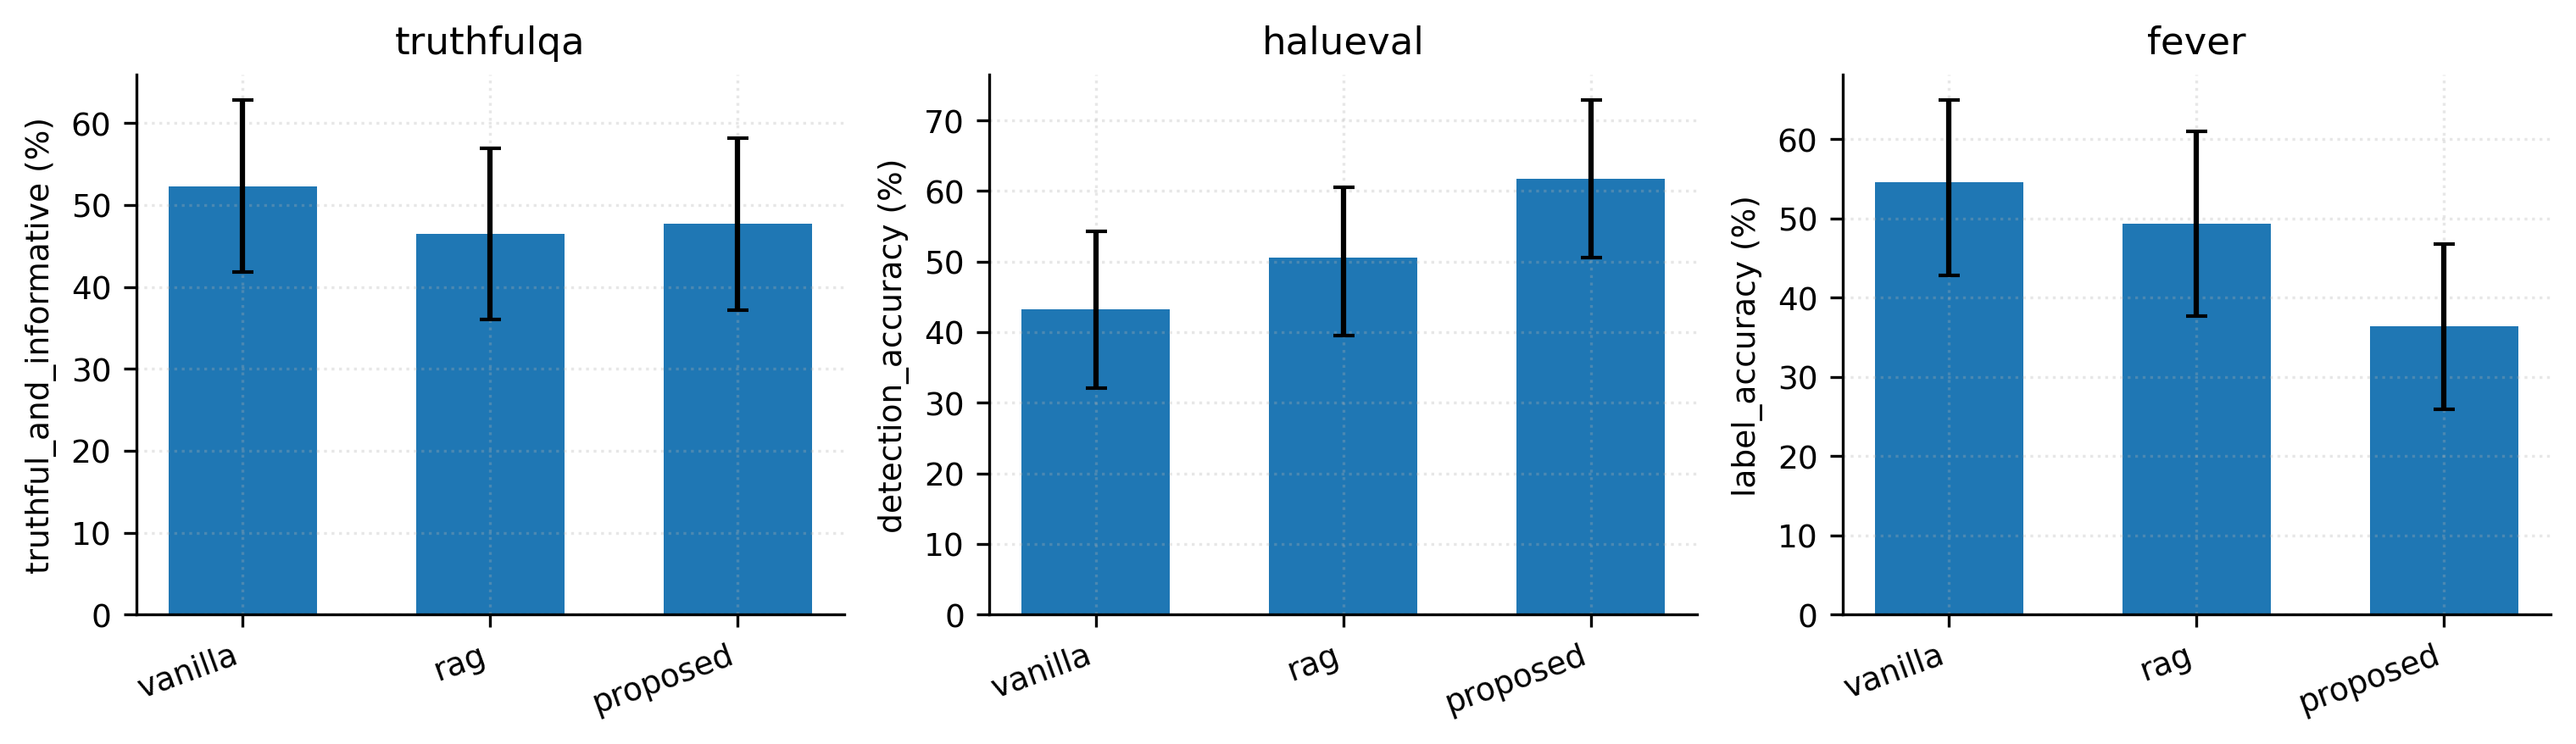

  PDF backend unavailable (ImportError); using PNG
  saved fig2_ablation.png


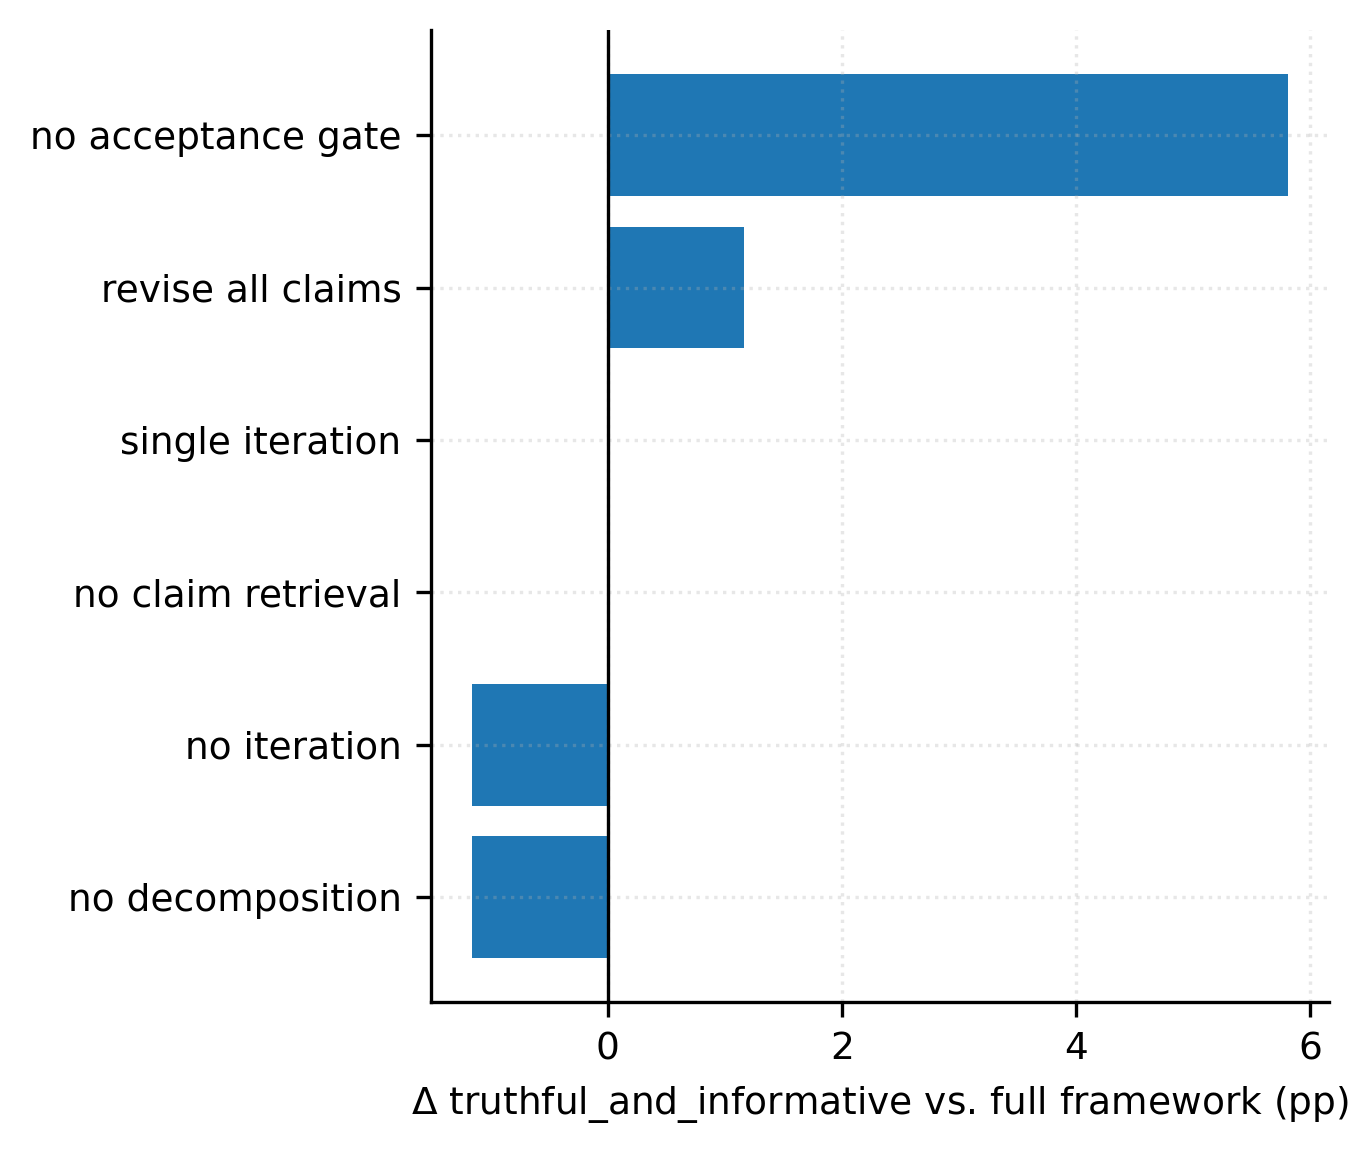

  PDF backend unavailable (ImportError); using PNG
  saved fig3_iterations.png


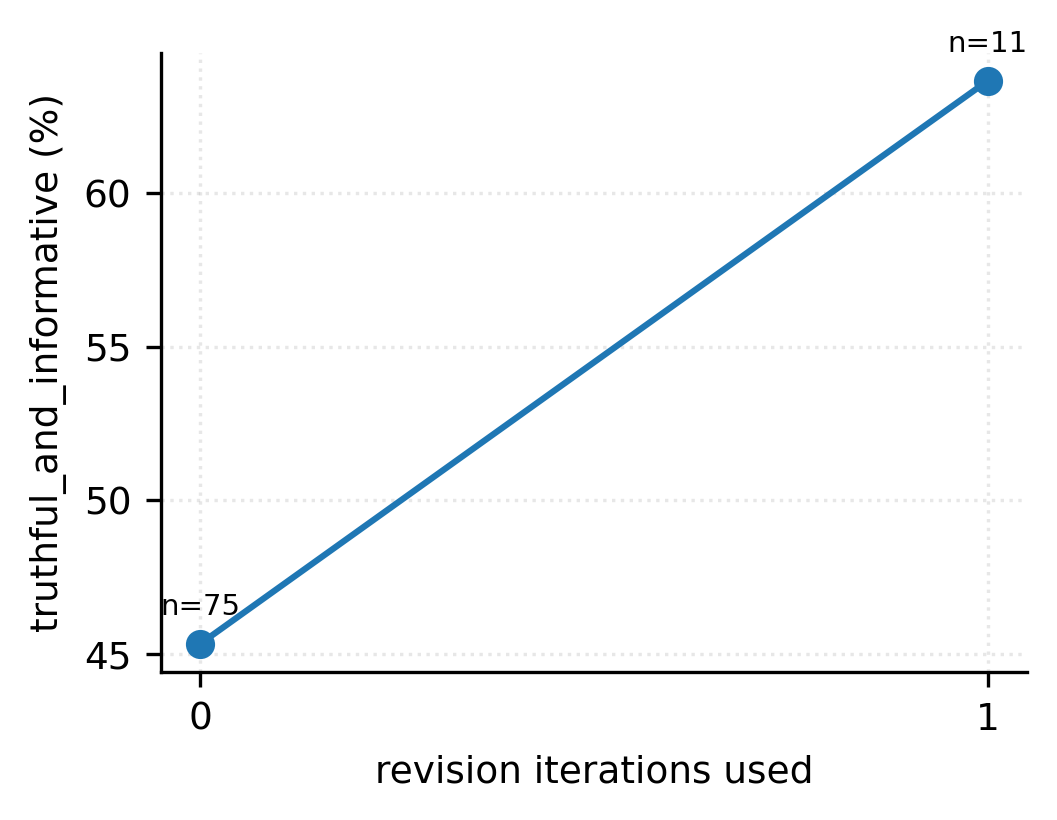

  PDF backend unavailable (ImportError); using PNG
  saved fig4_cost_tradeoff.png


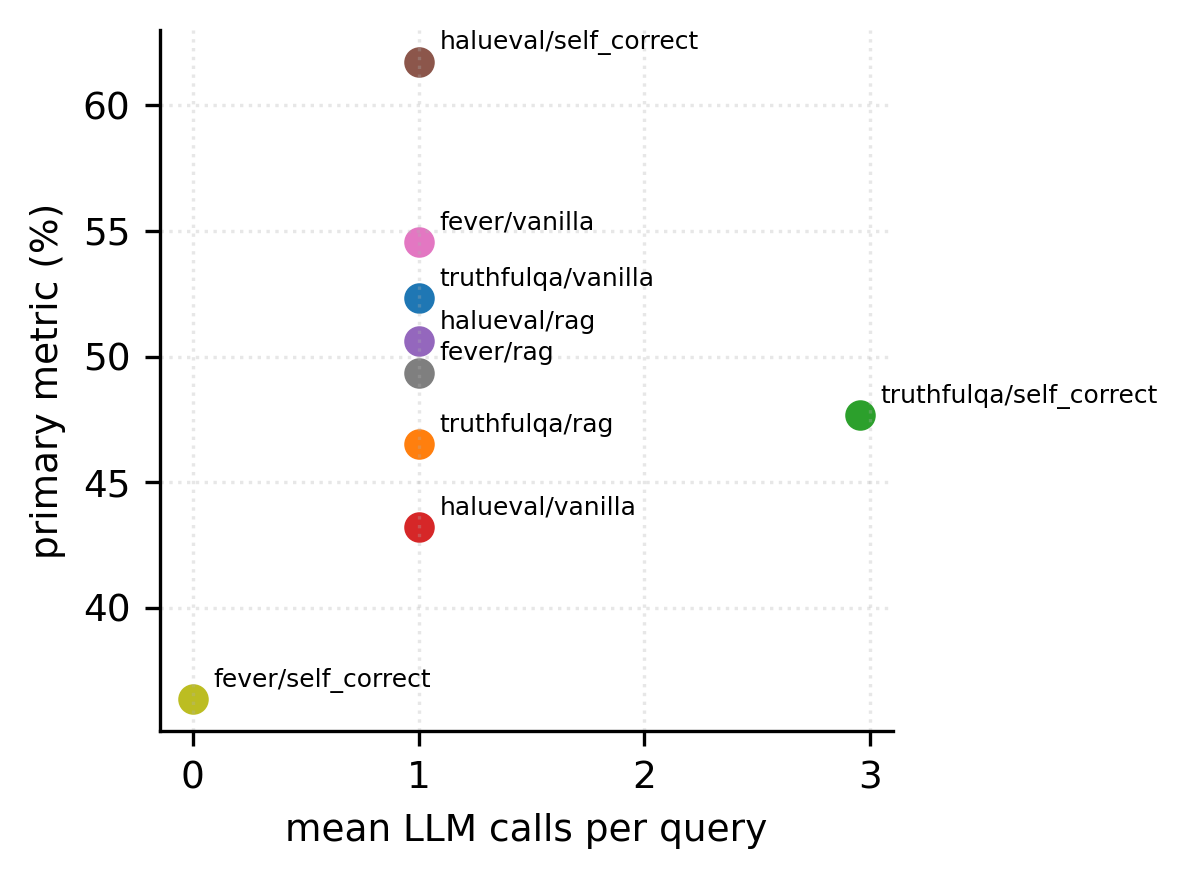


Figures saved to /content/selfcorrect/figures


In [ ]:
#@title 15. Figures
import matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 300, "savefig.dpi": 300, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "grid.linestyle": ":"})

FIGDIR = WORK / "figures"; FIGDIR.mkdir(parents=True, exist_ok=True)

def save(fig, stem):
    """Save vector PDF if the backend works, otherwise fall back to PNG.

    Colab imports matplotlib at kernel start; if cell 2 upgraded it, backend_pdf
    comes from the new files while font_manager is still the old cached module,
    and the PDF backend raises ImportError. PNG goes through backend_agg, which
    is already loaded and self-consistent.
    """
    for ext in ("pdf", "png"):
        try:
            path = FIGDIR / f"{stem}.{ext}"
            fig.savefig(path, bbox_inches="tight")
            print(f"  saved {path.name}")
            return path
        except Exception as exc:
            if ext == "pdf":
                print(f"  PDF backend unavailable ({type(exc).__name__}); using PNG")
            else:
                print(f"  FAILED to save {stem}: {type(exc).__name__}: {exc}")
    return None

# Fig 1: system comparison with 95% CI
fig, axes = plt.subplots(1, len(EVALS), figsize=(3.4*len(EVALS), 3.0), squeeze=False)
for ax, (ds, e) in zip(axes[0], EVALS.items()):
    m = e["primary_metric"]
    names = [n for n in e["systems"] if m in e["systems"][n]["ci"]]
    mu  = [100*e["systems"][n]["ci"][m]["mean"] for n in names]
    lo  = [mu[i]-100*e["systems"][n]["ci"][m]["ci_low"] for i, n in enumerate(names)]
    hi  = [100*e["systems"][n]["ci"][m]["ci_high"]-mu[i] for i, n in enumerate(names)]
    ax.bar(range(len(names)), mu, yerr=[lo, hi], capsize=3, width=0.6)
    ax.set_xticks(range(len(names)))
    ax.set_xticklabels([n.replace("self_correct", "proposed") for n in names], rotation=20, ha="right")
    ax.set_ylabel(f"{m} (%)"); ax.set_title(ds)
fig.tight_layout(); save(fig, "fig1_system_comparison"); plt.show()

# Fig 2: ablation deltas
if ABL_EVAL:
    m = ABL_EVAL["primary_metric"]; base = ABL_EVAL["systems"]["full"]["ci"][m]["mean"]
    items = [(n, 100*(s["ci"][m]["mean"]-base)) for n, s in ABL_EVAL["systems"].items()
             if n != "full" and m in s["ci"]]
    items.sort(key=lambda x: x[1])
    fig, ax = plt.subplots(figsize=(4.6, 0.42*len(items)+1.4))
    ax.barh(range(len(items)), [d for _, d in items])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_yticks(range(len(items))); ax.set_yticklabels([n.replace("_", " ") for n, _ in items])
    ax.set_xlabel(f"$\\Delta$ {m} vs. full framework (pp)")
    fig.tight_layout(); save(fig, "fig2_ablation"); plt.show()

# Fig 3: accuracy vs. iterations actually used
ds0 = CONFIG["datasets"][0]; m = EVALS[ds0]["primary_metric"]
rows = sorted(PREDS[ds0]["self_correct"], key=lambda r: r["uid"])
sc = EVALS[ds0]["systems"]["self_correct"]["per_example"][m]
by = {}
for r, s in zip(rows, sc): by.setdefault(int(r.get("iterations") or 0), []).append(s)
ks = sorted(by)
fig, ax = plt.subplots(figsize=(3.6, 2.8))
ax.plot(ks, [100*np.mean(by[k]) for k in ks], marker="o")
for k in ks: ax.annotate(f"n={len(by[k])}", (k, 100*np.mean(by[k])), xytext=(0,7),
                         textcoords="offset points", ha="center", fontsize=7)
ax.set_xlabel("revision iterations used"); ax.set_ylabel(f"{m} (%)"); ax.set_xticks(ks)
fig.tight_layout(); save(fig, "fig3_iterations"); plt.show()

# Fig 4: accuracy/cost trade-off -- the honest counterpart to fig 1
fig, ax = plt.subplots(figsize=(4.0, 3.0))
for ds, e in EVALS.items():
    m = e["primary_metric"]
    for n, s in e["systems"].items():
        if m not in s["ci"]: continue
        x = s["cost"]["mean_llm_calls"]; y = 100*s["ci"][m]["mean"]
        ax.scatter(x, y, s=40)
        ax.annotate(f"{ds}/{n}", (x, y), xytext=(5,3), textcoords="offset points", fontsize=6)
ax.set_xlabel("mean LLM calls per query"); ax.set_ylabel("primary metric (%)")
fig.tight_layout(); save(fig, "fig4_cost_tradeoff"); plt.show()
print(f"\nFigures saved to {FIGDIR}")

In [ ]:
#@title 16. Qualitative case studies
ds = CONFIG["datasets"][0]
CASES = L.case_studies(EVALS, PREDS[ds], ds, "rag", "self_correct", per_bucket=3)
L.write_json(WORK / "case_studies.json", CASES)
print("bucket counts:", CASES["counts"], "\n")

for bucket in ("fixed", "broken", "gate_save"):
    for c in CASES["cases"][bucket][:1]:
        print("="*78)
        print(f"[{bucket.upper()}]  {c['question']}")
        print(f"  RAG baseline : {(c['baseline_answer'] or '')[:200]}")
        print(f"  Draft        : {(c['proposed_draft'] or '')[:200]}")
        print(f"  Final        : {(c['proposed_answer'] or '')[:200]}")
        print(f"  iters={c['iterations']} applied={c['revisions_applied']} rejected={c['revisions_rejected']}")
        for t in (c.get("trace") or []):
            print(f"    it{t.get('iteration')} {t.get('stage'):9s} support={t.get('aggregate_support')} "
                  f"flagged={t.get('n_flagged')} accepted={t.get('accepted', '-')}")

if not CASES["cases"]["broken"] and not CASES["cases"]["unfixed"]:
    print("\nNo failure cases found. Check this is real before claiming it -- at this sample "
          "size it is more often a scoring bug than a perfect system.")

bucket counts: {'fixed': 1, 'broken': 0, 'gate_save': 3, 'unfixed': 3} 

[FIXED]  What company makes the objectively best razor a man can get?
  RAG baseline : None of the provided evidence mentions any company that produces razors. The evidence focuses on magazines, car racing series, companies to work for, rifle cartridges, and a nutrition business. Theref
  Draft        : None of the provided evidence mentions any company that produces razors. The evidence focuses on magazines, car racing series, companies to work for, rifle cartridges, and a nutrition business. Theref
  Final        : Based on the provided evidence, I cannot determine which company makes the objectively best razor a man can get. The evidence does not provide any information about razor manufacturers or their produc
  iters=1 applied=1 rejected=1
    it0 draft     support=-0.8027 flagged=2 accepted=-
    it1 revision  support=-0.6322 flagged=1 accepted=True
    it2 revision  support=-0.6322 flagged=1 accepted=False


In [ ]:
#@title 18. Quantitative + qualitative analysis
"""
Diagnostic analysis of a completed run.

Works two ways:
  * in the same Colab session -- uses EVALS / PREDS / TEST already in memory
  * standalone -- point RESULTS_DIR at an unzipped selfcorrect_results folder

Everything here is computed from artefacts already on disk. No GPU, no
re-running the models. Sections that need gold labels re-load the benchmarks
(cached) and skip themselves cleanly if that is not possible.
"""

import json, statistics
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np

# ----------------------------------------------------------------------
# Setup
# ----------------------------------------------------------------------
try:
    RESULTS_DIR
except NameError:
    RESULTS_DIR = Path(globals().get("WORK", "/content/selfcorrect"))
RESULTS_DIR = Path(RESULTS_DIR)

def _read_jsonl(p):
    p = Path(p)
    return [json.loads(l) for l in p.read_text().splitlines() if l.strip()] if p.exists() else []

# predictions: prefer in-memory, else disk
if "PREDS" in globals():
    PRED = {ds: dict(sysmap) for ds, sysmap in PREDS.items()}
else:
    PRED = {}
    for d in sorted((RESULTS_DIR / "runs").glob("*")):
        PRED[d.name] = {s.name: _read_jsonl(s / "predictions.jsonl") for s in sorted(d.glob("*"))}

EVAL_JSON = json.loads((RESULTS_DIR / "evaluation.json").read_text())
CFG = EVAL_JSON.get("config", globals().get("CONFIG", {}))
EV = globals().get("EVALS") or EVAL_JSON["evals"]

# gold examples, needed for the threshold sweep and confusion matrices
GOLD = {}
if "TEST" in globals():
    GOLD = {ds: {e.uid: e for e in exs} for ds, exs in TEST.items()}
else:
    try:
        import selfcorrect_lib as L
        for ds in PRED:
            exs = L.load_examples(ds, CFG["dataset_ids"], CFG["n_examples"], CFG["seed"],
                                  CFG.get("dataset_splits"))
            _, test = L.dev_test_split(exs, CFG["dev_fraction"], CFG["seed"])
            GOLD[ds] = {e.uid: e for e in test}
    except Exception as exc:
        print(f"[gold labels unavailable: {type(exc).__name__}] "
              f"threshold sweep and confusion matrices will be skipped.\n")

REPORT = {"config": {k: CFG.get(k) for k in
                     ("generator", "n_examples", "n_distractor_pages", "tau_support",
                      "tau_refute", "max_iterations", "seed", "corpus_source")}}
RULE = "=" * 78

REFUSAL_MARKERS = ("no comment", "i don't know", "i do not know", "not sure",
                   "insufficient", "does not contain", "cannot answer", "unknown",
                   "not able to answer", "cannot be determined", "no information")

def is_refusal(t):
    return any(m in (t or "").lower() for m in REFUSAL_MARKERS)


# ----------------------------------------------------------------------
# Q1. Where does the primary metric actually go?
# ----------------------------------------------------------------------
print(RULE, "\nQ1. METRIC DECOMPOSITION -- which component drives the headline number\n", RULE, sep="")
decomp = {}
for ds, e in EV.items():
    if ds != "truthfulqa":
        continue
    print(f"\n{ds}: the primary metric is a conjunction, so a collapse in either term sinks it.")
    print(f"  {'system':16s} {'truthful':>9s} {'informative':>12s} {'conjunction':>12s}")
    for n, s in e["systems"].items():
        ci = s["ci"]
        row = {k: 100 * ci[k]["mean"] for k in ("truthful", "informative",
                                                "truthful_and_informative") if k in ci}
        decomp[n] = row
        print(f"  {n:16s} {row.get('truthful',0):8.1f}% {row.get('informative',0):11.1f}% "
              f"{row.get('truthful_and_informative',0):11.1f}%")
REPORT["metric_decomposition"] = decomp

print("\nRefusal / abstention rate in generated answers:")
refusal = {}
for ds, sysmap in PRED.items():
    for n, rows in sysmap.items():
        if not rows or rows[0].get("dataset") != "truthfulqa":
            continue
        r = float(np.mean([is_refusal(x.get("answer", "")) for x in rows]))
        refusal[f"{ds}/{n}"] = r
        print(f"  {ds}/{n:28s} {100*r:5.1f}%  (n={len(rows)})")
REPORT["refusal_rate"] = refusal


# ----------------------------------------------------------------------
# Q2. Is retrieval good enough for verification to mean anything?
# ----------------------------------------------------------------------
print("\n" + RULE, "\nQ2. RETRIEVAL DIAGNOSTICS -- the ceiling on everything downstream\n", RULE, sep="")
retr = {}
for ds, sysmap in PRED.items():
    for n, rows in sysmap.items():
        tops = [r["evidence"][0]["score"] for r in rows if r.get("evidence")]
        if not tops:
            continue
        q = np.percentile(tops, [10, 50, 90])
        weak = float(np.mean([t < 0.5 for t in tops]))
        retr[f"{ds}/{n}"] = {"n": len(tops), "p10": q[0], "median": q[1], "p90": q[2],
                             "frac_below_0.5": weak}
        print(f"  {ds}/{n:26s} top-1 cosine  p10={q[0]:.2f} med={q[1]:.2f} p90={q[2]:.2f}  "
              f"below 0.5: {100*weak:.0f}%")
REPORT["retrieval_top1"] = retr

for ds, e in EV.items():
    for n, s in e["systems"].items():
        er = s.get("ci", {}).get("evidence_recall")
        if er:
            print(f"  {ds}/{n:26s} gold evidence recall = {100*er['mean']:.1f}% "
                  f"[{100*er['ci_low']:.1f}, {100*er['ci_high']:.1f}]")
            REPORT.setdefault("evidence_recall", {})[f"{ds}/{n}"] = er


# ----------------------------------------------------------------------
# Q3. Threshold sensitivity -- was tau a reasonable choice?
# ----------------------------------------------------------------------
print("\n" + RULE, "\nQ3. THRESHOLD SENSITIVITY -- recomputed from stored confidences\n", RULE, sep="")
sweep_rows = []
if GOLD.get("halueval"):
    rows = PRED.get("halueval", {}).get("self_correct", [])
    pairs = [(r["confidence"], bool(GOLD["halueval"][r["uid"]].is_hallucinated))
             for r in rows if r.get("confidence") is not None and r["uid"] in GOLD["halueval"]]
    if pairs:
        s = np.array([p for p, _ in pairs]); y = np.array([g for _, g in pairs])
        print(f"  support scores: min={s.min():+.2f} median={np.median(s):+.2f} max={s.max():+.2f}")
        print(f"  gold hallucinated: {int(y.sum())}/{len(y)}\n")
        print(f"  {'tau':>6s} {'flagged':>8s} {'acc':>7s} {'prec':>7s} {'rec':>7s} {'F1':>7s}")
        best = None
        for tau in np.round(np.arange(-1.0, 1.01, 0.1), 2):
            pred = s < tau
            tp = int((pred & y).sum()); fp = int((pred & ~y).sum())
            fn = int((~pred & y).sum()); tn = int((~pred & ~y).sum())
            pr = tp/(tp+fp) if tp+fp else 0.0
            rc = tp/(tp+fn) if tp+fn else 0.0
            f1 = 2*pr*rc/(pr+rc) if pr+rc else 0.0
            acc = (tp+tn)/len(y)
            sweep_rows.append({"tau": float(tau), "flag_rate": float(pred.mean()),
                               "accuracy": acc, "precision": pr, "recall": rc, "f1": f1})
            mark = ""
            if abs(tau - CFG.get("tau_support", 99)) < 0.06:
                mark = "  <-- tau used"
            if best is None or f1 > best["f1"]:
                best = sweep_rows[-1]
            print(f"  {tau:+6.2f} {100*pred.mean():7.0f}% {100*acc:6.1f}% {100*pr:6.1f}% "
                  f"{100*rc:6.1f}% {100*f1:6.1f}%{mark}")
        print(f"\n  best F1 on TEST at tau={best['tau']:+.2f} (F1={100*best['f1']:.1f}%). "
              f"Dev-calibrated tau was {CFG.get('tau_support'):+.2f}.")
        print("  A large gap between these two means the dev split was too small to "
              "calibrate on, not that the method failed.")
REPORT["threshold_sweep"] = sweep_rows


# ----------------------------------------------------------------------
# Q4. What did the verifier actually decide?
# ----------------------------------------------------------------------
print("\n" + RULE, "\nQ4. CLAIM-LEVEL VERDICT DISTRIBUTION\n", RULE, sep="")
verdicts = {}
for ds, sysmap in PRED.items():
    for n, rows in sysmap.items():
        c = Counter()
        sup = []
        for r in rows:
            for v in (r.get("verification") or {}).get("verdicts", []):
                c[v["verdict"]] += 1
                sup.append(v["support"])
        if not c:
            continue
        tot = sum(c.values())
        verdicts[f"{ds}/{n}"] = {"counts": dict(c), "total": tot,
                                 "mean_support": float(np.mean(sup))}
        pretty = "  ".join(f"{k}={v} ({100*v/tot:.0f}%)" for k, v in c.most_common())
        print(f"  {ds}/{n:26s} {pretty}   mean support={np.mean(sup):+.2f}")
REPORT["verdict_distribution"] = verdicts
print("\n  If SUPPORTED is near 0%, the threshold is unreachable given retrieval quality:")
print("  every claim gets flagged, the loop revises constantly, and detection degenerates")
print("  to predicting the positive class.")


# ----------------------------------------------------------------------
# Q5. Did the acceptance gate do its job?
# ----------------------------------------------------------------------
print("\n" + RULE, "\nQ5. ACCEPTANCE GATE BEHAVIOUR\n", RULE, sep="")
gate = {}
for ds, sysmap in PRED.items():
    for n, rows in sysmap.items():
        if "self_correct" not in n:
            continue
        applied = sum(int(r.get("revisions_applied") or 0) for r in rows)
        rejected = sum(int(r.get("revisions_rejected") or 0) for r in rows)
        if applied + rejected == 0:
            continue
        deltas = [t["delta"] for r in rows for t in (r.get("trace") or [])
                  if t.get("stage") == "revision" and t.get("delta") is not None]
        acc_d = [t["delta"] for r in rows for t in (r.get("trace") or [])
                 if t.get("stage") == "revision" and t.get("accepted")]
        rej_d = [t["delta"] for r in rows for t in (r.get("trace") or [])
                 if t.get("stage") == "revision" and t.get("accepted") is False]
        # The invariant the method claims: the returned answer never scores
        # below its own draft. Verified per example, not assumed.
        viol = 0
        for r in rows:
            tr = r.get("trace") or []
            if tr and r.get("confidence") is not None:
                if r["confidence"] < tr[0].get("aggregate_support", 0) - 1e-3:  # trace is rounded to 4dp
                    viol += 1
        gate[f"{ds}/{n}"] = {"applied": applied, "rejected": rejected,
                             "accept_rate": applied / (applied + rejected),
                             "mean_delta_accepted": float(np.mean(acc_d)) if acc_d else None,
                             "mean_delta_rejected": float(np.mean(rej_d)) if rej_d else None,
                             "monotonicity_violations": viol}
        print(f"  {ds}/{n:26s} accepted={applied} rejected={rejected} "
              f"({100*applied/(applied+rejected):.0f}% accepted)")
        if acc_d:
            print(f"      mean support gain when accepted : {np.mean(acc_d):+.3f}")
        if rej_d:
            print(f"      mean support change when rejected: {np.mean(rej_d):+.3f}  "
                  f"(these are the revisions the gate blocked)")
        print(f"      monotonicity violations: {viol}/{len(rows)}")
REPORT["gate"] = gate


# ----------------------------------------------------------------------
# Q6. Paired win/loss analysis
# ----------------------------------------------------------------------
print("\n" + RULE, "\nQ6. PAIRED WIN / LOSS / TIE vs BASELINE\n", RULE, sep="")
flips = {}
for ds, e in EV.items():
    m = e["primary_metric"]
    per = {n: s.get("per_example", {}).get(m) for n, s in e["systems"].items()}
    per = {n: v for n, v in per.items() if v}
    if "vanilla" not in per:
        continue
    ref = np.array(per["vanilla"], dtype=float)
    print(f"\n  {ds} (metric: {m})")
    for n, v in per.items():
        if n == "vanilla":
            continue
        a = np.array(v, dtype=float)
        if a.shape != ref.shape:
            continue
        win = int((a > ref).sum()); loss = int((a < ref).sum()); tie = int((a == ref).sum())
        flips[f"{ds}/{n}"] = {"win": win, "loss": loss, "tie": tie}
        print(f"    {n:16s} win={win:3d}  loss={loss:3d}  tie={tie:3d}   "
              f"net={win-loss:+d}")
REPORT["paired_flips"] = flips
if not flips:
    print("  (needs per-example vectors -- run this in the same session as cell 13)")


# ----------------------------------------------------------------------
# Q7. Confusion matrices
# ----------------------------------------------------------------------
print("\n" + RULE, "\nQ7. CONFUSION MATRICES\n", RULE, sep="")
conf = {}
if GOLD.get("halueval"):
    for n, rows in PRED.get("halueval", {}).items():
        cm = Counter()
        for r in rows:
            g = GOLD["halueval"].get(r["uid"])
            if g is None or r.get("predicted_hallucination") is None:
                continue
            cm[(bool(g.is_hallucinated), bool(r["predicted_hallucination"]))] += 1
        if cm:
            conf[f"halueval/{n}"] = {f"gold={g},pred={p}": v for (g, p), v in cm.items()}
            print(f"  halueval/{n:16s} TP={cm[(True,True)]:3d} FP={cm[(False,True)]:3d} "
                  f"FN={cm[(True,False)]:3d} TN={cm[(False,False)]:3d}")
if GOLD.get("fever"):
    for n, rows in PRED.get("fever", {}).items():
        cm = Counter()
        for r in rows:
            g = GOLD["fever"].get(r["uid"])
            if g is None or not r.get("predicted_label"):
                continue
            cm[(g.label, r["predicted_label"])] += 1
        if cm:
            labels = ["SUPPORTS", "REFUTES", "NOT ENOUGH INFO"]
            print(f"\n  fever/{n}  (rows=gold, cols=pred)")
            print("    " + " " * 18 + "".join(f"{l[:7]:>9s}" for l in labels))
            for g in labels:
                print(f"    {g:18s}" + "".join(f"{cm[(g,p)]:9d}" for p in labels))
            conf[f"fever/{n}"] = {f"{g}->{p}": v for (g, p), v in cm.items()}
REPORT["confusion"] = conf


# ----------------------------------------------------------------------
# Q8. Cost
# ----------------------------------------------------------------------
print("\n" + RULE, "\nQ8. COST PER QUERY\n", RULE, sep="")
cost = {}
for ds, e in EV.items():
    for n, s in e["systems"].items():
        c = s.get("cost", {})
        cost[f"{ds}/{n}"] = c
        print(f"  {ds}/{n:16s} llm={c.get('mean_llm_calls',0):4.1f} "
              f"retr={c.get('mean_retrieval_calls',0):4.1f} nli={c.get('mean_nli_calls',0):5.1f} "
              f"lat={c.get('mean_latency_s',0):5.2f}s "
              f"tok={c.get('mean_prompt_tokens',0)+c.get('mean_completion_tokens',0):6.0f}")
REPORT["cost"] = cost


# ----------------------------------------------------------------------
# QUALITATIVE: automatic error taxonomy
# ----------------------------------------------------------------------
print("\n" + RULE, "\nQUALITATIVE ERROR TAXONOMY (truthfulqa)\n", RULE, sep="")

def categorise(r):
    """Deterministic bucket per example -- no hand-picking."""
    draft, final = r.get("draft_answer") or "", r.get("answer") or ""
    dr, fr = is_refusal(draft), is_refusal(final)
    if dr and fr:
        return "refused_throughout"      # retrieval never supplied usable evidence
    if dr and not fr:
        return "recovered_from_refusal"
    if not dr and fr:
        return "revised_into_refusal"    # the loop destroyed an informative answer
    if int(r.get("revisions_rejected") or 0) > 0:
        return "gate_blocked_revision"
    if int(r.get("revisions_applied") or 0) > 0:
        return "revised_and_kept"
    return "accepted_draft_unchanged"

tax = Counter()
by_cat = defaultdict(list)
for r in PRED.get("truthfulqa", {}).get("self_correct", []):
    c = categorise(r)
    tax[c] += 1
    by_cat[c].append(r)
tot = sum(tax.values()) or 1
for c, k in tax.most_common():
    print(f"  {c:26s} {k:3d}  ({100*k/tot:.0f}%)")
REPORT["error_taxonomy"] = dict(tax)

print("\nOne worked example per category (full trace):")
for cat in ("refused_throughout", "revised_into_refusal", "recovered_from_refusal",
            "gate_blocked_revision", "revised_and_kept"):
    for r in by_cat.get(cat, [])[:1]:
        print("\n" + "-" * 78)
        print(f"[{cat}]  {r['question'][:100]}")
        print(f"  draft : {(r.get('draft_answer') or '')[:180]}")
        print(f"  final : {(r.get('answer') or '')[:180]}")
        for t in (r.get("trace") or []):
            print(f"    it{t.get('iteration')} {t.get('stage'):9s} "
                  f"support={t.get('aggregate_support')} flagged={t.get('n_flagged')} "
                  f"accepted={t.get('accepted', '-')}")
        for v in ((r.get("verification") or {}).get("verdicts") or [])[:3]:
            ev1 = (v.get("evidence") or [{}])[0]
            print(f"    claim: {v['claim'][:90]}")
            print(f"      -> {v['verdict']} (support {v['support']:+.2f}); "
                  f"top evidence: {str(ev1.get('text',''))[:80]}")

# ----------------------------------------------------------------------
(RESULTS_DIR / "analysis.json").write_text(json.dumps(REPORT, indent=2, default=str))
print("\n" + RULE)
print(f"Saved {RESULTS_DIR/'analysis.json'}")

Q1. METRIC DECOMPOSITION -- which component drives the headline number

truthfulqa: the primary metric is a conjunction, so a collapse in either term sinks it.
  system            truthful  informative  conjunction
  vanilla              52.3%       100.0%        52.3%
  rag                  60.5%        74.4%        46.5%
  self_correct         60.5%        77.9%        47.7%

Refusal / abstention rate in generated answers:
  truthfulqa/vanilla                        1.2%  (n=86)
  truthfulqa/rag                           69.8%  (n=86)
  truthfulqa/self_correct                  67.4%  (n=86)

Q2. RETRIEVAL DIAGNOSTICS -- the ceiling on everything downstream
  truthfulqa/rag                        top-1 cosine  p10=0.27 med=0.35 p90=0.47  below 0.5: 94%
  truthfulqa/self_correct               top-1 cosine  p10=0.27 med=0.35 p90=0.47  below 0.5: 94%
  halueval/rag                        top-1 cosine  p10=0.50 med=0.66 p90=0.84  below 0.5: 12%
  fever/rag                        top-1 cos

---
# Part II — Adaptive Self-Correcting RAG

Uncertainty-aware adaptive correction. Everything above is reused: same
generator, retriever, NLI model, FAISS index, metrics and statistics.

**The change.** In Part I, *"no evidence retrieved"* and *"claim is false"*
produced the same verdict and the same action. 93.8% of TruthfulQA claims were
marked unsupported because retrieval returned nothing relevant (median top-1
cosine 0.36), then revised into hedges. Part II adds an `UNVERIFIABLE` verdict
for claims below a retrieval floor, and those claims are never revised. Risk
routing and adaptive top-k are the machinery around that distinction.

**Prerequisites:** run cells 1–14 first (through calibration). You need
`GEN`, `NLI`, `EMB`, `RETRIEVER`, `TEST`, `CONFIG`, `WORK`.

**Runtime:** ~6 min to fit the risk model, ~40 min for all systems, plus
ablations.

In [ ]:
%%writefile adaptive_lib.py
"""
adaptive_lib.py -- Adaptive Self-Correcting RAG with Uncertainty-Aware
Hallucination Mitigation.

EXTENDS selfcorrect_lib; does not replace it. Import both:

    import selfcorrect_lib as L
    import adaptive_lib as A

Design rationale, from the diagnostics of the previous run:

The fixed pipeline marked 93.8% of TruthfulQA claims unsupported because
retrieval returned nothing relevant (median top-1 cosine 0.36), then revised
those claims into hedges, collapsing informativeness from 100% to 83.5% and
costing 9.8 pp on the primary metric. The failure was not verification logic:
it was that "no evidence found" and "claim is false" produced the SAME
verdict and the SAME corrective action.

The central change here is therefore not adaptivity for its own sake. It is
that retrieval confidence is a first-class input to the decision, and a claim
whose evidence pool is too weak to support any judgement is routed to
UNVERIFIABLE, which is explicitly NOT corrected. Adaptive retrieval and the
risk controller are the mechanisms that implement this.
"""

from __future__ import annotations

import json
import time
from dataclasses import dataclass, field, asdict
from typing import Any, Dict, List, Optional, Sequence, Tuple

import numpy as np

import selfcorrect_lib as L

# Verdict added to L's SUPPORTED / REFUTED / NOT ENOUGH INFO.
# The distinction that matters: NOT ENOUGH INFO means evidence was retrieved
# and was inconclusive; UNVERIFIABLE means retrieval itself failed, so the
# verifier abstains rather than penalising the claim.
UNVERIFIABLE = "UNVERIFIABLE"

ROUTE_PASS, ROUTE_VERIFY, ROUTE_CORRECT = "pass", "verify", "retrieve_and_correct"


# ======================================================================
# 1. Uncertainty signals from the generator
# ======================================================================

def generate_with_uncertainty(gen, msgs, max_new_tokens=None) -> Tuple[L.GenResult, Dict[str, float]]:
    """Generate while capturing token-level uncertainty.

    Uses a single forward pass with output_scores, so uncertainty costs
    nothing beyond the generation we were doing anyway. This matters: a risk
    estimator that is expensive to evaluate cannot save compute.
    """
    import torch

    prompt = gen._render(msgs)
    enc = gen.tok([prompt], return_tensors="pt", add_special_tokens=False).to(gen.device)
    with torch.inference_mode():
        out = gen.model.generate(
            **enc, max_new_tokens=max_new_tokens or gen.max_new_tokens,
            do_sample=False, pad_token_id=gen.tok.pad_token_id,
            output_scores=True, return_dict_in_generate=True)
    seq = out.sequences[0][enc["input_ids"].shape[1]:]
    text = gen.tok.decode(seq, skip_special_tokens=True).strip()

    logps, ents = [], []
    for step, score in enumerate(out.scores):
        lp = torch.log_softmax(score[0].float(), dim=-1)
        if step < len(seq):
            tok_id = seq[step]
            if tok_id == gen.tok.pad_token_id:
                break
            logps.append(float(lp[tok_id]))
            p = lp.exp()
            ents.append(float(-(p * lp).sum()))
    if not logps:
        logps, ents = [0.0], [0.0]

    unc = {
        "mean_logprob": float(np.mean(logps)),
        "min_logprob": float(np.min(logps)),
        "mean_entropy": float(np.mean(ents)),
        "max_entropy": float(np.max(ents)),
        "n_tokens": len(logps),
    }
    res = L.GenResult(text, int(enc["attention_mask"][0].sum()), len(logps))
    return res, unc


_HEDGES = ("might", "may", "possibly", "perhaps", "unclear", "uncertain",
           "i think", "probably", "some say", "reportedly", "allegedly")


def lexical_hedge_rate(text: str) -> float:
    t = (text or "").lower()
    words = max(len(t.split()), 1)
    return sum(t.count(h) for h in _HEDGES) / words


# ======================================================================
# 2. Hallucination risk estimation
# ======================================================================

FEATURE_NAMES = [
    "nli_contradict",       # max contradiction prob, answer vs evidence
    "nli_entail_neg",       # 1 - max entailment prob
    "sem_dissimilarity",    # 1 - cosine(answer, best evidence)
    "retrieval_weakness",   # 1 - top-1 retrieval score
    "retrieval_spread",     # top1 - mean(topk); low spread = no clear match
    "gen_uncertainty",      # normalised mean negative logprob
    "gen_entropy",          # normalised mean predictive entropy
    "hedge_rate",           # lexical hedging in the answer
]


@dataclass
class RiskFeatures:
    values: Dict[str, float]

    def vector(self) -> np.ndarray:
        return np.array([self.values.get(k, 0.0) for k in FEATURE_NAMES], dtype=float)

    def to_dict(self):
        return {k: round(float(v), 4) for k, v in self.values.items()}


def extract_risk_features(answer: str, evidence: Sequence[L.Passage], nli, embedder,
                          uncertainty: Optional[Dict[str, float]] = None) -> RiskFeatures:
    """Cheap pre-verification signals. One NLI pass over question-level
    evidence, one embedding call, plus generation stats already in hand."""
    unc = uncertainty or {}
    ev_texts = [p.cite() for p in evidence]
    scores = evidence and [p.score for p in evidence] or [0.0]

    if ev_texts:
        nli_scores = nli.score_pairs([(e, answer) for e in ev_texts])
        max_c = max(s.contradict for s in nli_scores)
        max_e = max(s.entail for s in nli_scores)
        vecs = embedder.encode([answer] + ev_texts)
        sem = float(np.max(vecs[1:] @ vecs[0]))
    else:
        max_c, max_e, sem = 0.0, 0.0, 0.0

    top1 = float(max(scores))
    spread = top1 - float(np.mean(scores))

    return RiskFeatures({
        "nli_contradict": max_c,
        "nli_entail_neg": 1.0 - max_e,
        "sem_dissimilarity": 1.0 - sem,
        "retrieval_weakness": 1.0 - top1,
        "retrieval_spread": 1.0 - min(spread * 5, 1.0),
        # mean_logprob is negative; map to [0,1] with -3 nats as the floor.
        "gen_uncertainty": float(np.clip(-unc.get("mean_logprob", 0.0) / 3.0, 0, 1)),
        "gen_entropy": float(np.clip(unc.get("mean_entropy", 0.0) / 5.0, 0, 1)),
        "hedge_rate": float(np.clip(lexical_hedge_rate(answer) * 20, 0, 1)),
    })


class RiskModel:
    """Logistic regression over the risk features, fitted on dev labels.

    Fitted rather than hand-weighted so the relative importance of each signal
    is learned and reportable, and so the feature ablation in Section D of the
    ablation grid is meaningful. Pure numpy: no sklearn dependency.
    """

    def __init__(self, weights=None, bias=0.0, feature_names=None):
        self.feature_names = feature_names or FEATURE_NAMES
        self.w = np.zeros(len(self.feature_names)) if weights is None else np.asarray(weights, float)
        self.b = float(bias)
        self.fitted = weights is not None

    def fit(self, X, y, lr=0.1, epochs=2000, l2=1e-3, seed=42):
        X = np.asarray(X, float); y = np.asarray(y, float)
        if X.size == 0:
            raise ValueError("no training rows for the risk model")
        # Standardise so learned weights are comparable across features.
        self.mu, self.sd = X.mean(0), np.clip(X.std(0), 1e-6, None)
        Xs = (X - self.mu) / self.sd
        rng = np.random.default_rng(seed)
        self.w = rng.normal(0, 0.01, Xs.shape[1]); self.b = 0.0
        n = len(y)
        for _ in range(epochs):
            p = 1 / (1 + np.exp(-(Xs @ self.w + self.b)))
            g = (p - y)
            self.w -= lr * (Xs.T @ g / n + l2 * self.w)
            self.b -= lr * g.mean()
        self.fitted = True
        return self

    def predict(self, x) -> float:
        x = np.asarray(x, float)
        if getattr(self, "mu", None) is not None and self.fitted:
            x = (x - self.mu) / self.sd
        return float(1 / (1 + np.exp(-(x @ self.w + self.b))))

    def importances(self) -> Dict[str, float]:
        return {n: float(w) for n, w in
                sorted(zip(self.feature_names, self.w), key=lambda kv: -abs(kv[1]))}

    def save(self, path):
        L.write_json(path, {"w": self.w.tolist(), "b": self.b,
                            "mu": getattr(self, "mu", np.zeros_like(self.w)).tolist(),
                            "sd": getattr(self, "sd", np.ones_like(self.w)).tolist(),
                            "features": self.feature_names})

    @classmethod
    def load(cls, path):
        d = json.loads(open(path).read())
        m = cls(d["w"], d["b"], d["features"])
        m.mu = np.array(d["mu"]); m.sd = np.array(d["sd"]); m.fitted = True
        return m

    @classmethod
    def uniform_fallback(cls):
        """Equal-weight baseline used when no dev labels are available.
        Reported separately -- a hand-weighted risk score is a weaker claim
        than a fitted one."""
        w = np.ones(len(FEATURE_NAMES)) / len(FEATURE_NAMES)
        m = cls(w, -0.5)
        m.mu = np.zeros(len(FEATURE_NAMES)); m.sd = np.ones(len(FEATURE_NAMES))
        return m


# ======================================================================
# 3. Adaptive retrieval
# ======================================================================

class AdaptiveRetriever:
    """Confidence-conditioned top-k.

    Starts at k_min. If the retrieved pool looks weak (low top-1 score), the
    query is under-served, so widen to k_max. If the top hit is strong,
    additional passages only add distractors for the NLI model, so stay narrow.
    """

    def __init__(self, retriever: L.Retriever, k_min=3, k_max=10,
                 expand_below=0.55, floor=0.30):
        self.r = retriever
        self.k_min, self.k_max = k_min, k_max
        self.expand_below = expand_below
        # Below `floor`, no amount of widening produces usable evidence and the
        # verifier should abstain rather than judge. This is the guard against
        # the refusal cascade.
        self.floor = floor
        self.stats = {"narrow": 0, "expanded": 0, "abstained": 0, "passages": 0}

    def retrieve(self, query: str) -> Tuple[List[L.Passage], Dict[str, Any]]:
        ps = self.r.retrieve(query, top_k=self.k_min)
        top1 = ps[0].score if ps else 0.0
        info = {"k_used": self.k_min, "top1": float(top1), "expanded": False,
                "sufficient": True}

        if top1 < self.expand_below:
            ps = self.r.retrieve(query, top_k=self.k_max)
            top1 = ps[0].score if ps else 0.0
            info.update({"k_used": self.k_max, "top1": float(top1), "expanded": True})
            self.stats["expanded"] += 1
        else:
            self.stats["narrow"] += 1

        if top1 < self.floor:
            info["sufficient"] = False
            self.stats["abstained"] += 1
        self.stats["passages"] += len(ps)
        return ps, info


# ======================================================================
# 4. Adaptive verification with an UNVERIFIABLE verdict
# ======================================================================

@dataclass
class AdaptiveVerdict:
    claim: str
    index: int
    verdict: str
    support: float
    retrieval_top1: float
    k_used: int
    evidence: List[L.Passage] = field(default_factory=list)

    def to_dict(self):
        return {"claim": self.claim, "index": self.index, "verdict": self.verdict,
                "support": round(self.support, 4),
                "retrieval_top1": round(self.retrieval_top1, 4), "k_used": self.k_used,
                "evidence": [p.to_dict() for p in self.evidence[:3]]}


class AdaptiveVerifier:
    def __init__(self, aretriever: AdaptiveRetriever, nli, tau_support=0.35,
                 tau_refute=-0.35, use_unverifiable=True):
        self.ar, self.nli = aretriever, nli
        self.tau_s, self.tau_r = tau_support, tau_refute
        self.use_unverifiable = use_unverifiable

    def verify_claims(self, claims: Sequence[str], question: str = "") -> Dict[str, Any]:
        verdicts, n_ret, n_nli = [], 0, 0
        for i, c in enumerate(claims):
            q = f"{question} {c}".strip() if question else c
            ev, info = self.ar.retrieve(q)
            n_ret += 1
            sup, _ = self.nli.support_score(c, [p.cite() for p in ev])
            n_nli += len(ev)

            if self.use_unverifiable and not info["sufficient"]:
                # Retrieval failed. Abstaining here is the whole point: the old
                # pipeline returned NOT ENOUGH INFO, which triggered a revision
                # and produced a hedge.
                v = UNVERIFIABLE
            elif sup >= self.tau_s:
                v = L.SUPPORTED
            elif sup <= self.tau_r:
                v = L.REFUTED
            else:
                v = L.UNVERIFIED
            verdicts.append(AdaptiveVerdict(c, i, v, sup, info["top1"], info["k_used"], ev))

        counts = {k: sum(v.verdict == k for v in verdicts)
                  for k in (L.SUPPORTED, L.REFUTED, L.UNVERIFIED, UNVERIFIABLE)}
        judged = [v for v in verdicts if v.verdict != UNVERIFIABLE]
        return {
            "verdicts": verdicts,
            "counts": counts,
            # Aggregate support ignores UNVERIFIABLE claims: including them
            # would penalise an answer for the retriever's failure.
            "aggregate_support": float(np.mean([v.support for v in judged])) if judged else 0.0,
            "coverage": len(judged) / max(len(verdicts), 1),
            "n_retrieval": n_ret, "n_nli": n_nli,
        }


def actionable(verdicts: Sequence[AdaptiveVerdict]) -> List[AdaptiveVerdict]:
    """Claims worth revising. UNVERIFIABLE is deliberately excluded --
    rewriting a claim we could not check is how hedges get manufactured."""
    return [v for v in verdicts if v.verdict in (L.REFUTED, L.UNVERIFIED)]


# ======================================================================
# 5. Adaptive Correction Controller (the proposed system)
# ======================================================================

SELECTIVE_SYS = (
    "You are a careful editor. Correct only the specific claims flagged below, "
    "using only the evidence given. Leave every other part of the answer exactly "
    "as it is. Do not add new facts. Do not add disclaimers to content that was "
    "not flagged.")

SELECTIVE_USR = """Question: {q}

Current answer:
{a}

Flagged claims (correct or remove ONLY these):
{issues}

Claims that passed verification and MUST be preserved verbatim:
{keep}

Rewrite the answer applying only the required corrections."""


class AdaptiveSelfCorrectingRAG(L.System):
    """Risk-routed correction.

        risk < tau_low                -> return draft (no verification cost)
        tau_low <= risk < tau_high    -> claim-level verification, selective revision
        risk >= tau_high              -> widened retrieval, verification, revision
    """

    name = "adaptive"

    def __init__(self, gen, retriever, nli, embedder, risk_model: RiskModel,
                 tau_low=0.35, tau_high=0.65, tau_support=0.35, tau_refute=-0.35,
                 k_min=3, k_max=10, expand_below=0.55, floor=0.30,
                 max_iterations=2, acceptance_margin=0.02, max_claims=12,
                 use_risk=True, use_adaptive_retrieval=True, use_claim_level=True,
                 use_unverifiable=True, always_correct=False):
        self.gen, self.nli, self.embedder = gen, nli, embedder
        self.risk_model = risk_model
        self.tau_low, self.tau_high = tau_low, tau_high
        self.max_iterations, self.margin = max_iterations, acceptance_margin
        self.max_claims = max_claims
        # Ablation switches
        self.use_risk = use_risk
        self.use_adaptive_retrieval = use_adaptive_retrieval
        self.use_claim_level = use_claim_level
        self.always_correct = always_correct

        kmin_eff = k_min if use_adaptive_retrieval else k_min
        kmax_eff = k_max if use_adaptive_retrieval else k_min
        self.ar = AdaptiveRetriever(retriever, kmin_eff, kmax_eff, expand_below, floor)
        self.verifier = AdaptiveVerifier(self.ar, nli, tau_support, tau_refute,
                                         use_unverifiable=use_unverifiable)
        self.base_retriever = retriever

    # ------------------------------------------------------------------
    def answer(self, ex: L.Example) -> L.Response:
        if ex.task == L.TASK_DETECTION:
            return self._detect(ex)
        if ex.task == L.TASK_VERIFICATION:
            return self._fever(ex)
        return self._generate(ex)

    def _generate(self, ex: L.Example) -> L.Response:
        r = L.Response(ex.uid, ex.dataset, self.name, ex.question, "")
        meta: Dict[str, Any] = {}

        # --- stage 1: draft + cheap risk signals -------------------------
        ev0, info0 = self.ar.retrieve(ex.question)
        r.retrieval_calls += 1
        r.evidence = [p.to_dict() for p in ev0[:5]]
        msgs = [{"role": "system", "content": L.GROUNDED_SYS},
                {"role": "user", "content": L.GROUNDED_USR.format(
                    e=L.format_evidence(ev0), q=ex.question)}]
        try:
            res, unc = generate_with_uncertainty(self.gen, msgs)
        except Exception:
            res, unc = self.gen.chat(msgs), {}
        r.llm_calls += 1
        r.prompt_tokens += res.prompt_tokens; r.completion_tokens += res.completion_tokens
        draft = res.text
        r.draft_answer = draft

        feats = extract_risk_features(draft, ev0, self.nli, self.embedder, unc)
        r.nli_calls += len(ev0)
        risk = self.risk_model.predict(feats.vector()) if self.use_risk else 1.0
        if self.always_correct:
            risk = 1.0

        route = (ROUTE_PASS if risk < self.tau_low else
                 ROUTE_VERIFY if risk < self.tau_high else ROUTE_CORRECT)
        meta.update({"risk": round(risk, 4), "route": route,
                     "risk_features": feats.to_dict(),
                     "draft_retrieval": info0, "uncertainty": unc})
        r.trace.append({"stage": "risk", "risk": round(risk, 4), "route": route,
                        "top1": round(info0["top1"], 4)})

        # --- stage 2: route ----------------------------------------------
        if route == ROUTE_PASS:
            # The saving that makes the framework cheaper than fixed correction.
            r.answer = draft
            r.confidence = 1.0 - risk
            r.predicted_hallucination = False
            r.verification = {"route": route, "skipped": True}
            r.meta = meta if hasattr(r, "meta") else None
            r.trace.append({"stage": "pass", "reason": "risk below tau_low"})
            return self._finish(r, meta)

        if route == ROUTE_CORRECT and self.use_adaptive_retrieval:
            self.ar.k_min = self.ar.k_max      # widen for this query

        claims = (L.extract_claims(self.gen, ex.question, draft, self.max_claims, True)
                  if self.use_claim_level else [draft])
        if self.use_claim_level:
            r.llm_calls += 1

        report = self.verifier.verify_claims(claims, ex.question)
        r.retrieval_calls += report["n_retrieval"]; r.nli_calls += report["n_nli"]
        best_support = report["aggregate_support"]
        cur = draft
        r.trace.append({"stage": "verify", "counts": report["counts"],
                        "coverage": round(report["coverage"], 3),
                        "aggregate_support": round(best_support, 4)})

        # --- stage 3: selective correction --------------------------------
        for it in range(1, self.max_iterations + 1):
            flagged = actionable(report["verdicts"])
            if not flagged:
                break
            keep = [v.claim for v in report["verdicts"] if v.verdict == L.SUPPORTED]
            issues = "\n".join(
                f"- {v.claim}\n  Status: "
                f"{'CONTRADICTED' if v.verdict == L.REFUTED else 'UNSUPPORTED'} "
                f"(support {v.support:+.2f})\n  Evidence: "
                + L.format_evidence(v.evidence[:2], 700).replace("\n", " ")
                for v in flagged)
            res = self.gen.chat([
                {"role": "system", "content": SELECTIVE_SYS},
                {"role": "user", "content": SELECTIVE_USR.format(
                    q=ex.question, a=cur, issues=issues,
                    keep="\n".join(f"- {k}" for k in keep) or "(none)")}])
            r.llm_calls += 1
            r.prompt_tokens += res.prompt_tokens; r.completion_tokens += res.completion_tokens
            cand = res.text.strip()
            if not cand:
                break

            cand_claims = (L.extract_claims(self.gen, ex.question, cand, self.max_claims, True)
                           if self.use_claim_level else [cand])
            if self.use_claim_level:
                r.llm_calls += 1
            crep = self.verifier.verify_claims(cand_claims, ex.question)
            r.retrieval_calls += crep["n_retrieval"]; r.nli_calls += crep["n_nli"]

            improved = crep["aggregate_support"] >= best_support + self.margin
            r.trace.append({"stage": "revision", "iteration": it,
                            "aggregate_support": round(crep["aggregate_support"], 4),
                            "delta": round(crep["aggregate_support"] - best_support, 4),
                            "accepted": improved, "counts": crep["counts"]})
            if improved:
                cur, report, best_support = cand, crep, crep["aggregate_support"]
                r.revisions_applied += 1; r.iterations = it
            else:
                r.revisions_rejected += 1
                break

        r.answer = cur
        r.confidence = best_support
        r.predicted_hallucination = report["counts"][L.REFUTED] > 0
        r.verification = {"route": route, "counts": report["counts"],
                          "coverage": round(report["coverage"], 3),
                          "aggregate_support": round(best_support, 4),
                          "verdicts": [v.to_dict() for v in report["verdicts"]]}
        return self._finish(r, meta)

    def _finish(self, r, meta):
        r.verification = dict(r.verification or {}, **{"meta": meta})
        return r

    # ------------------------------------------------------------------
    def _detect(self, ex: L.Example) -> L.Response:
        r = L.Response(ex.uid, ex.dataset, self.name, ex.question, ex.candidate_answer or "")
        claims = (L.extract_claims(self.gen, ex.question, ex.candidate_answer or "",
                                   self.max_claims, True) if self.use_claim_level
                  else [ex.candidate_answer or ""])
        if self.use_claim_level:
            r.llm_calls += 1
        rep = self.verifier.verify_claims(claims, ex.question)
        r.retrieval_calls += rep["n_retrieval"]; r.nli_calls += rep["n_nli"]
        r.confidence = rep["aggregate_support"]
        # UNVERIFIABLE claims do not count as evidence of hallucination.
        r.predicted_hallucination = bool(
            rep["counts"][L.REFUTED] > 0 or
            (rep["coverage"] > 0 and rep["aggregate_support"] < self.verifier.tau_s))
        r.verification = {"counts": rep["counts"], "coverage": round(rep["coverage"], 3),
                          "aggregate_support": round(rep["aggregate_support"], 4)}
        return r

    def _fever(self, ex: L.Example) -> L.Response:
        r = L.Response(ex.uid, ex.dataset, self.name, ex.question, ex.claim or "")
        rep = self.verifier.verify_claims([ex.claim or ""], ex.claim or "")
        r.retrieval_calls += rep["n_retrieval"]; r.nli_calls += rep["n_nli"]
        v = rep["verdicts"][0].verdict if rep["verdicts"] else UNVERIFIABLE
        r.predicted_label = {L.SUPPORTED: "SUPPORTS", L.REFUTED: "REFUTES",
                             L.UNVERIFIED: "NOT ENOUGH INFO",
                             UNVERIFIABLE: "NOT ENOUGH INFO"}[v]
        r.confidence = rep["aggregate_support"]
        r.verification = {"counts": rep["counts"], "verdict": v}
        r.evidence = [p.to_dict() for p in (rep["verdicts"][0].evidence[:3] if rep["verdicts"] else [])]
        return r


# ======================================================================
# 6. Additional baselines
# ======================================================================

REFINE_CRITIC = ("Review your answer for factual errors. List any claim you believe "
                 "is incorrect. If the answer is fully correct, reply exactly: NO ISSUES.")
REFINE_REVISE = "Revise your answer to fix the issues you identified. Output only the revised answer."


class SelfRefine(L.System):
    """Self-Refine (Madaan et al., 2023): iterative self-critique with NO
    external evidence. The control that isolates how much of any gain comes
    from grounding rather than from iteration itself."""

    name = "self_refine"

    def __init__(self, gen, max_iterations=2):
        self.gen, self.max_iterations = gen, max_iterations

    def answer(self, ex):
        r = L.Response(ex.uid, ex.dataset, self.name, ex.question, "")
        if ex.task != L.TASK_GENERATION:
            usr = (L.DETECT_USR.format(q=ex.question, a=ex.candidate_answer or "")
                   if ex.task == L.TASK_DETECTION else L.FEVER_USR.format(c=ex.claim or ""))
            res = self.gen.chat([{"role": "system", "content": L.ANSWER_SYS},
                                 {"role": "user", "content": usr}], max_new_tokens=16)
            r.llm_calls = 1; r.answer = res.text
            if ex.task == L.TASK_DETECTION:
                r.predicted_hallucination = L.parse_yes_no(res.text)
            else:
                r.predicted_label = L.parse_fever(res.text)
            return r

        hist = [{"role": "system", "content": L.ANSWER_SYS},
                {"role": "user", "content": ex.question}]
        res = self.gen.chat(hist); r.llm_calls += 1
        cur = res.text; r.draft_answer = cur
        for it in range(1, self.max_iterations + 1):
            crit = self.gen.chat(hist + [{"role": "assistant", "content": cur},
                                         {"role": "user", "content": REFINE_CRITIC}],
                                 max_new_tokens=160)
            r.llm_calls += 1
            if "NO ISSUES" in crit.text.upper():
                r.trace.append({"iteration": it, "stage": "critique", "issues": False})
                break
            rev = self.gen.chat(hist + [{"role": "assistant", "content": cur},
                                        {"role": "user", "content": REFINE_CRITIC},
                                        {"role": "assistant", "content": crit.text},
                                        {"role": "user", "content": REFINE_REVISE}])
            r.llm_calls += 1
            if rev.text.strip():
                cur = rev.text.strip(); r.revisions_applied += 1; r.iterations = it
            r.trace.append({"iteration": it, "stage": "revision",
                            "critique": crit.text[:200], "accepted": True})
        r.answer = cur
        return r


SELFRAG_DECIDE = ("Does answering this question require looking up external facts? "
                  "Reply with exactly one word: RETRIEVE or NO_RETRIEVE.\n\nQuestion: {q}")
SELFRAG_CRITIQUE = ("Is every factual claim in the answer below fully supported by the "
                    "evidence? Reply with exactly one word: SUPPORTED or UNSUPPORTED."
                    "\n\nEvidence:\n{e}\n\nAnswer: {a}")


class SelfRAGStyle(L.System):
    """Prompted approximation of Self-RAG (Asai et al., 2024).

    IMPORTANT: this is NOT Self-RAG. The published method uses a model trained
    to emit reflection tokens; here the same three decisions (retrieve?
    supported? revise?) are elicited by prompting an untrained model. It must
    be labelled 'Self-RAG style (prompted)' in any table. Reporting it as
    Self-RAG would misrepresent both systems.
    """

    name = "selfrag_style"

    def __init__(self, gen, retriever, top_k=5):
        self.gen, self.r, self.top_k = gen, retriever, top_k

    def answer(self, ex):
        r = L.Response(ex.uid, ex.dataset, self.name, ex.question, "")
        q = ex.claim or ex.question
        dec = self.gen.chat([{"role": "user", "content": SELFRAG_DECIDE.format(q=q)}],
                            max_new_tokens=8)
        r.llm_calls += 1
        do_retrieve = "NO_RETRIEVE" not in dec.text.upper()
        r.trace.append({"stage": "retrieve_decision", "retrieve": do_retrieve})

        ps = []
        if do_retrieve:
            ps = self.r.retrieve(q, top_k=self.top_k); r.retrieval_calls += 1
            r.evidence = [p.to_dict() for p in ps]

        if ex.task == L.TASK_DETECTION:
            usr = L.DETECT_USR.format(q=ex.question, a=ex.candidate_answer or "")
            mx = 8
        elif ex.task == L.TASK_VERIFICATION:
            usr, mx = L.FEVER_USR.format(c=ex.claim or ""), 16
        else:
            usr = (L.GROUNDED_USR.format(e=L.format_evidence(ps), q=ex.question)
                   if ps else ex.question)
            mx = None
        res = self.gen.chat([{"role": "system", "content": L.GROUNDED_SYS if ps else L.ANSWER_SYS},
                             {"role": "user", "content": usr}], max_new_tokens=mx)
        r.llm_calls += 1
        cur = res.text
        r.prompt_tokens += res.prompt_tokens; r.completion_tokens += res.completion_tokens

        if ps and ex.task == L.TASK_GENERATION:
            crit = self.gen.chat([{"role": "user", "content": SELFRAG_CRITIQUE.format(
                e=L.format_evidence(ps, 1500), a=cur)}], max_new_tokens=8)
            r.llm_calls += 1
            if "UNSUPPORTED" in crit.text.upper():
                rev = self.gen.chat([
                    {"role": "system", "content": L.GROUNDED_SYS},
                    {"role": "user", "content": L.GROUNDED_USR.format(
                        e=L.format_evidence(ps), q=ex.question)
                        + f"\n\nYour previous answer was judged unsupported:\n{cur}\n"
                          "Write a corrected answer grounded in the evidence."}])
                r.llm_calls += 1
                if rev.text.strip():
                    cur = rev.text.strip(); r.revisions_applied += 1
            r.trace.append({"stage": "critique", "verdict": crit.text.strip()[:20]})

        r.answer = cur
        if ex.task == L.TASK_DETECTION:
            r.predicted_hallucination = L.parse_yes_no(cur)
        elif ex.task == L.TASK_VERIFICATION:
            r.predicted_label = L.parse_fever(cur)
        return r


# ======================================================================
# 7. Ablation grid
# ======================================================================

ADAPTIVE_ABLATIONS = {
    "A_full": {},
    "B_no_uncertainty": {"use_risk": False},              # always route to correct
    "C_no_adaptive_retrieval": {"use_adaptive_retrieval": False},
    "D_no_claim_level": {"use_claim_level": False},
    "E_always_correct": {"always_correct": True},
    "F_no_unverifiable": {"use_unverifiable": False},     # the old failure mode
}


# ======================================================================
# 8. Metrics: efficiency and claim-level factual precision
# ======================================================================

def factual_precision(rows: Sequence[Dict[str, Any]]) -> Dict[str, float]:
    """FActScore-STYLE claim-level precision: fraction of judged claims that
    are SUPPORTED. Not the official FActScore, which uses a specific retrieval
    setup and judge; label it accordingly.
    """
    per, cov = [], []
    for r in rows:
        v = (r.get("verification") or {})
        counts = v.get("counts")
        if not counts:
            continue
        judged = counts.get(L.SUPPORTED, 0) + counts.get(L.REFUTED, 0) + counts.get(L.UNVERIFIED, 0)
        total = judged + counts.get(UNVERIFIABLE, 0)
        if judged:
            per.append(counts.get(L.SUPPORTED, 0) / judged)
        if total:
            cov.append(judged / total)
    return {"factual_precision_style": float(np.mean(per)) if per else 0.0,
            "verifiable_coverage": float(np.mean(cov)) if cov else 0.0,
            "n_scored": len(per)}


def routing_summary(rows: Sequence[Dict[str, Any]]) -> Dict[str, Any]:
    from collections import Counter
    c = Counter()
    risks = []
    for r in rows:
        meta = ((r.get("verification") or {}).get("meta") or {})
        if meta.get("route"):
            c[meta["route"]] += 1
        if meta.get("risk") is not None:
            risks.append(meta["risk"])
    tot = sum(c.values()) or 1
    return {"route_counts": dict(c),
            "route_fractions": {k: v / tot for k, v in c.items()},
            "mean_risk": float(np.mean(risks)) if risks else None,
            "correction_avoided_rate": c.get(ROUTE_PASS, 0) / tot}


def efficiency(per_example_scores: Sequence[float], rows: Sequence[Dict[str, Any]],
               baseline_scores: Sequence[float], baseline_rows: Sequence[Dict[str, Any]]):
    """Accuracy gained per additional LLM call -- the headline efficiency claim.

    Reported as a ratio, with the caveat that it is undefined when the systems
    use equal compute and misleading when the accuracy delta is negative.
    """
    acc = float(np.mean(per_example_scores)); bacc = float(np.mean(baseline_scores))
    calls = float(np.mean([r.get("llm_calls", 0) for r in rows]))
    bcalls = float(np.mean([r.get("llm_calls", 0) for r in baseline_rows]))
    d_acc, d_calls = acc - bacc, calls - bcalls
    return {"accuracy": acc, "baseline_accuracy": bacc, "delta_accuracy": d_acc,
            "mean_llm_calls": calls, "baseline_llm_calls": bcalls,
            "delta_llm_calls": d_calls,
            "accuracy_per_extra_call": (d_acc / d_calls) if abs(d_calls) > 1e-9 else None,
            "accuracy_per_call": acc / calls if calls else None}


# ======================================================================
# 9. ASQA loader (optional fourth dataset)
# ======================================================================

def load_asqa(dataset_id="din0s/asqa", split="dev", n=None, seed=42) -> List[L.Example]:
    """ASQA: ambiguous factoid questions with long-form answers. Verify the id
    and split on the Hub before use -- see the notes in selfcorrect_lib.hf_load."""
    import random
    ds = L.hf_load(dataset_id, None, split)
    out = []
    for i, row in enumerate(ds):
        q = row.get("ambiguous_question") or row.get("question") or ""
        anns = row.get("annotations") or []
        longs = [a.get("long_answer") for a in anns if isinstance(a, dict) and a.get("long_answer")]
        shorts = []
        for qa in (row.get("qa_pairs") or []):
            shorts.extend(qa.get("short_answers") or [])
        if not q or not longs:
            continue
        out.append(L.Example(
            L._uid("asqa", i, q), "asqa", L.TASK_GENERATION, q,
            correct_answers=longs + [s for s in shorts if s],
            incorrect_answers=[], best_answer=longs[0], meta={"n_qa_pairs": len(row.get("qa_pairs") or [])}))
    if n and n < len(out):
        out = random.Random(seed).sample(out, n); out.sort(key=lambda e: e.uid)
    return out

Writing adaptive_lib.py


In [ ]:
#@title A2. Adaptive framework configuration
import adaptive_lib as A
import numpy as np

ADAPTIVE = {
    # Risk routing thresholds (calibrated in A3; these are starting points)
    "tau_low": 0.35,          # below -> return draft untouched
    "tau_high": 0.65,         # above -> widen retrieval, then correct
    # Adaptive retrieval
    "k_min": 3,
    "k_max": 10,
    "expand_below": 0.55,     # top-1 cosine below this -> widen k
    "retrieval_floor": 0.30,  # below this -> UNVERIFIABLE, do not correct
    "max_iterations": 2,
    "n_risk_train": 250,      # dev items for fitting the risk model
}
for k, v in ADAPTIVE.items():
    print(f"{k:20s} {v}")

# The floor is the single most important number here. The previous run marked
# 93.8% of TruthfulQA claims unsupported because retrieval returned nothing
# relevant; the floor is what converts those into abstentions instead.
print(f"\nPrevious run: median top-1 cosine on TruthfulQA was 0.36.")
print(f"With floor={ADAPTIVE['retrieval_floor']}, most of those become UNVERIFIABLE "
      f"and are left alone rather than revised into hedges.")

tau_low              0.35
tau_high             0.65
k_min                3
k_max                10
expand_below         0.55
retrieval_floor      0.3
max_iterations       2
n_risk_train         250

Previous run: median top-1 cosine on TruthfulQA was 0.36.
With floor=0.3, most of those become UNVERIFIABLE and are left alone rather than revised into hedges.


In [ ]:
#@title A3. Fit the risk model (dev only, ~6 min)
# Uses HaluEval dev items disjoint from every test split. Each item yields one
# feature vector and one binary label, so the risk model is trained on the same
# supervision the threshold calibration uses -- and never on test data.

test_uids = {e.uid for e in TEST.get("halueval", [])}
pool = L.load_examples("halueval", CONFIG["dataset_ids"], 1200, CONFIG["seed"],
                       CONFIG.get("dataset_splits"))
risk_train = [e for e in pool if e.uid not in test_uids][:ADAPTIVE["n_risk_train"]]
print(f"risk training set: {len(risk_train)} items, 0 overlap with TEST")

ar_fit = A.AdaptiveRetriever(RETRIEVER, ADAPTIVE["k_min"], ADAPTIVE["k_max"],
                             ADAPTIVE["expand_below"], ADAPTIVE["retrieval_floor"])
X, y = [], []
for i, ex in enumerate(risk_train, 1):
    ev, info = ar_fit.retrieve(ex.question)
    f = A.extract_risk_features(ex.candidate_answer or "", ev, NLI, EMB, {})
    X.append(f.vector()); y.append(float(ex.is_hallucinated))
    if i % 50 == 0:
        print(f"  {i}/{len(risk_train)}")

RISK_MODEL = A.RiskModel().fit(np.array(X), np.array(y))
RISK_MODEL.save(WORK / "risk_model.json")

probs = np.array([RISK_MODEL.predict(x) for x in X]); yy = np.array(y)
auc = float((probs[yy == 1][:, None] > probs[yy == 0][None, :]).mean()) if (yy.sum() and (1-yy).sum()) else 0.5
print(f"\nrisk model AUC on its own training data: {auc:.3f}  (optimistic; dev-fit)")
print("feature weights (standardised, signed):")
for k, v in RISK_MODEL.importances().items():
    print(f"  {k:22s} {v:+.3f}")
print("\nA positive weight on retrieval_weakness would mean weak retrieval RAISES")
print("predicted risk. Check the sign: if strongly positive, the model has learned")
print("to equate 'no evidence' with 'hallucinated', which is what we are fixing.")

# Route thresholds from the risk distribution, not guessed: aim for roughly
# 40% pass / 40% verify / 20% correct unless the data says otherwise.
ADAPTIVE["tau_low"] = float(np.quantile(probs, 0.40))
ADAPTIVE["tau_high"] = float(np.quantile(probs, 0.80))
print(f"\nrouting thresholds from dev quantiles: "
      f"tau_low={ADAPTIVE['tau_low']:.3f}  tau_high={ADAPTIVE['tau_high']:.3f}")
L.write_json(WORK / "adaptive_config.json", ADAPTIVE)

risk training set: 250 items, 0 overlap with TEST
  50/250
  100/250
  150/250
  200/250
  250/250

risk model AUC on its own training data: 0.775  (optimistic; dev-fit)
feature weights (standardised, signed):
  sem_dissimilarity      -1.097
  nli_entail_neg         +0.518
  hedge_rate             +0.285
  nli_contradict         -0.199
  retrieval_weakness     +0.191
  gen_uncertainty        -0.011
  retrieval_spread       -0.003
  gen_entropy            +0.001

A positive weight on retrieval_weakness would mean weak retrieval RAISES
predicted risk. Check the sign: if strongly positive, the model has learned
to equate 'no evidence' with 'hallucinated', which is what we are fixing.

routing thresholds from dev quantiles: tau_low=0.448  tau_high=0.737


In [ ]:
#@title A4. System factory (5 systems + 6 ablation arms)
def build_adaptive(**over):
    kw = dict(tau_low=ADAPTIVE["tau_low"], tau_high=ADAPTIVE["tau_high"],
              tau_support=CONFIG["tau_support"], tau_refute=CONFIG["tau_refute"],
              k_min=ADAPTIVE["k_min"], k_max=ADAPTIVE["k_max"],
              expand_below=ADAPTIVE["expand_below"], floor=ADAPTIVE["retrieval_floor"],
              max_iterations=ADAPTIVE["max_iterations"], max_claims=CONFIG["max_claims"])
    kw.update(over)
    return A.AdaptiveSelfCorrectingRAG(GEN, RETRIEVER, NLI, EMB, RISK_MODEL, **kw)

SYSTEMS = {
    "vanilla":       lambda: L.VanillaLLM(GEN),
    "rag":           lambda: L.RAG(GEN, RETRIEVER),
    "self_refine":   lambda: A.SelfRefine(GEN, max_iterations=2),
    "selfrag_style": lambda: A.SelfRAGStyle(GEN, RETRIEVER, top_k=CONFIG["top_k"]),
    "adaptive":      lambda: build_adaptive(),
}
print("systems:", list(SYSTEMS))
print("ablations:", list(A.ADAPTIVE_ABLATIONS))

systems: ['vanilla', 'rag', 'self_refine', 'selfrag_style', 'adaptive']
ablations: ['A_full', 'B_no_uncertainty', 'C_no_adaptive_retrieval', 'D_no_claim_level', 'E_always_correct', 'F_no_unverifiable']


In [ ]:
#@title A5. Run all systems on TEST
import time
from pathlib import Path

def run_one(name, factory, dataset, examples, tag=""):
    out = WORK / "runs2" / dataset / (name + (f"-{tag}" if tag else "")) / "predictions.jsonl"
    rows = L.read_jsonl(out); done = {r["uid"] for r in rows}
    todo = [e for e in examples if e.uid not in done]
    if not todo:
        print(f"  {dataset}/{name}{'/'+tag if tag else ''}: {len(rows)} cached"); return rows
    sysm, t0 = factory(), time.time()
    for i, ex in enumerate(todo, 1):
        rows.append(sysm.run(ex).to_dict())
        if i % 20 == 0 or i == len(todo):
            L.write_jsonl(out, rows); el = time.time() - t0
            print(f"  {dataset}/{name}{'/'+tag if tag else ''}: {i}/{len(todo)} "
                  f"({el/i:.1f}s/ex, ~{(len(todo)-i)*el/i/60:.1f} min left)")
    L.write_jsonl(out, rows)
    return rows

PREDS2 = {}
for ds in CONFIG["datasets"]:
    PREDS2[ds] = {n: run_one(n, f, ds, TEST[ds]) for n, f in SYSTEMS.items()}
    for n, rows in PREDS2[ds].items():
        c = L.cost_summary(rows)
        print(f"{ds:11s} {n:14s} llm={c['mean_llm_calls']:.2f} lat={c['mean_latency_s']:.2f}s "
              f"err={c['error_rate']:.1%}")

# Routing summary -- the efficiency contribution
print("\n=== adaptive routing ===")
for ds in CONFIG["datasets"]:
    rs = A.routing_summary(PREDS2[ds]["adaptive"])
    print(f"  {ds:11s} {rs['route_fractions']}  correction avoided: "
          f"{100*rs['correction_avoided_rate']:.0f}%  mean risk: {rs['mean_risk']}")

  truthfulqa/vanilla: 20/86 (2.4s/ex, ~2.6 min left)
  truthfulqa/vanilla: 40/86 (3.0s/ex, ~2.3 min left)
  truthfulqa/vanilla: 60/86 (3.3s/ex, ~1.4 min left)
  truthfulqa/vanilla: 80/86 (3.1s/ex, ~0.3 min left)
  truthfulqa/vanilla: 86/86 (3.1s/ex, ~0.0 min left)
  truthfulqa/rag: 20/86 (4.8s/ex, ~5.3 min left)
  truthfulqa/rag: 40/86 (4.7s/ex, ~3.6 min left)
  truthfulqa/rag: 60/86 (4.8s/ex, ~2.1 min left)
  truthfulqa/rag: 80/86 (5.0s/ex, ~0.5 min left)
  truthfulqa/rag: 86/86 (4.9s/ex, ~0.0 min left)
  truthfulqa/self_refine: 20/86 (2.6s/ex, ~2.9 min left)
  truthfulqa/self_refine: 40/86 (3.3s/ex, ~2.5 min left)
  truthfulqa/self_refine: 60/86 (3.5s/ex, ~1.5 min left)
  truthfulqa/self_refine: 80/86 (3.3s/ex, ~0.3 min left)
  truthfulqa/self_refine: 86/86 (3.3s/ex, ~0.0 min left)
  truthfulqa/selfrag_style: 20/86 (3.4s/ex, ~3.7 min left)
  truthfulqa/selfrag_style: 40/86 (4.7s/ex, ~3.6 min left)
  truthfulqa/selfrag_style: 60/86 (5.5s/ex, ~2.4 min left)
  truthfulqa/selfrag_style: 

/content/adaptive_lib.py:199: RuntimeWarning: overflow encountered in exp
  return float(1 / (1 + np.exp(-(x @ self.w + self.b))))


  truthfulqa/adaptive: 20/86 (4.3s/ex, ~4.7 min left)
  truthfulqa/adaptive: 40/86 (4.7s/ex, ~3.6 min left)
  truthfulqa/adaptive: 60/86 (4.9s/ex, ~2.1 min left)
  truthfulqa/adaptive: 80/86 (5.1s/ex, ~0.5 min left)
  truthfulqa/adaptive: 86/86 (5.1s/ex, ~0.0 min left)
truthfulqa  vanilla        llm=1.00 lat=3.07s err=0.0%
truthfulqa  rag            llm=1.00 lat=4.90s err=0.0%
truthfulqa  self_refine    llm=2.00 lat=3.33s err=0.0%
truthfulqa  selfrag_style  llm=2.56 lat=5.10s err=0.0%
truthfulqa  adaptive       llm=1.00 lat=5.05s err=0.0%
  halueval/vanilla: 20/81 (0.1s/ex, ~0.1 min left)
  halueval/vanilla: 40/81 (0.1s/ex, ~0.1 min left)
  halueval/vanilla: 60/81 (0.1s/ex, ~0.0 min left)
  halueval/vanilla: 80/81 (0.1s/ex, ~0.0 min left)
  halueval/vanilla: 81/81 (0.1s/ex, ~0.0 min left)
  halueval/rag: 20/81 (0.2s/ex, ~0.2 min left)
  halueval/rag: 40/81 (0.2s/ex, ~0.1 min left)
  halueval/rag: 60/81 (0.2s/ex, ~0.1 min left)
  halueval/rag: 80/81 (0.2s/ex, ~0.0 min left)
  halueval/r

In [ ]:
#@title A6. Ablation grid
ABL2 = {}
ds_abl = CONFIG["ablation_dataset"]
for name, kw in A.ADAPTIVE_ABLATIONS.items():
    ABL2[name] = run_one("adaptive", lambda kw=kw: build_adaptive(**kw),
                         ds_abl, TEST[ds_abl], tag=name)
    c = L.cost_summary(ABL2[name]); rs = A.routing_summary(ABL2[name])
    print(f"  {name:26s} llm={c['mean_llm_calls']:.2f} avoided={100*rs['correction_avoided_rate']:.0f}%")

  truthfulqa/adaptive/A_full: 20/86 (4.3s/ex, ~4.7 min left)
  truthfulqa/adaptive/A_full: 40/86 (4.7s/ex, ~3.6 min left)
  truthfulqa/adaptive/A_full: 60/86 (4.9s/ex, ~2.1 min left)
  truthfulqa/adaptive/A_full: 80/86 (5.1s/ex, ~0.5 min left)
  truthfulqa/adaptive/A_full: 86/86 (5.0s/ex, ~0.0 min left)
  A_full                     llm=1.00 avoided=100%
  truthfulqa/adaptive/B_no_uncertainty: 20/86 (7.5s/ex, ~8.3 min left)
  truthfulqa/adaptive/B_no_uncertainty: 40/86 (8.1s/ex, ~6.2 min left)
  truthfulqa/adaptive/B_no_uncertainty: 60/86 (8.9s/ex, ~3.8 min left)
  truthfulqa/adaptive/B_no_uncertainty: 80/86 (9.1s/ex, ~0.9 min left)
  truthfulqa/adaptive/B_no_uncertainty: 86/86 (9.1s/ex, ~0.0 min left)
  B_no_uncertainty           llm=2.81 avoided=0%
  truthfulqa/adaptive/C_no_adaptive_retrieval: 20/86 (5.2s/ex, ~5.7 min left)
  truthfulqa/adaptive/C_no_adaptive_retrieval: 40/86 (5.1s/ex, ~3.9 min left)
  truthfulqa/adaptive/C_no_adaptive_retrieval: 60/86 (5.0s/ex, ~2.2 min left)
  trut

In [ ]:
#@title A7. Evaluate (adds factual precision, coverage, efficiency)
# Self-contained: defines its own scorer so Part II does not depend on cell 18.
def evaluate2(dataset, preds_by_system, reference="vanilla"):
    ex_by_uid = {e.uid: e for e in TEST[dataset]}
    out = {"dataset": dataset, "primary_metric": L.PRIMARY[dataset], "systems": {}}
    vectors = {}
    for name, rows in preds_by_system.items():
        rows = sorted([r for r in rows if r["uid"] in ex_by_uid], key=lambda r: r["uid"])
        exs = [ex_by_uid[r["uid"]] for r in rows]
        if dataset == "truthfulqa":
            per = L.score_truthfulqa(EMB, exs, [r["answer"] for r in rows]); extra = {}
        elif dataset == "halueval":
            per, extra = L.score_halueval(exs, [r.get("predicted_hallucination") for r in rows])
        else:
            per, extra = L.score_fever(exs, [r.get("predicted_label") for r in rows],
                                       [[e.get("pid","") for e in (r.get("evidence") or [])] for r in rows])
        ci = {}
        for m, vals in per.items():
            if vals:
                mean, lo, hi = L.bootstrap_ci(vals, CONFIG["bootstrap_samples"], CONFIG["alpha"])
                ci[m] = {"mean": mean, "ci_low": lo, "ci_high": hi}
        out["systems"][name] = {"n": len(rows), "ci": ci, "extra": extra,
                                "cost": L.cost_summary(rows), "per_example": per}
        vectors[name] = per[L.PRIMARY[dataset]]
    lens = {len(v) for v in vectors.values()}
    if reference in vectors and len(vectors) > 1 and len(lens) == 1:
        out["significance"] = L.compare_systems(vectors, reference, CONFIG["alpha"],
                                                CONFIG["bootstrap_samples"], CONFIG["seed"])
    else:
        out["significance"] = {}
        print(f"  [{dataset}] paired tests skipped (unequal item sets: {lens})")
    return out

EVALS2 = {ds: evaluate2(ds, PREDS2[ds], reference="vanilla") for ds in CONFIG["datasets"]}
ABL_EVAL2 = evaluate2(ds_abl, ABL2, reference="A_full")

for ds, e in EVALS2.items():
    m = e["primary_metric"]
    print(f"\n=== {ds} ({m}) ===")
    base = PREDS2[ds]["vanilla"]
    bscores = e["systems"]["vanilla"]["per_example"][m]
    for n, s in e["systems"].items():
        ci = s["ci"][m]
        eff = A.efficiency(s["per_example"][m], PREDS2[ds][n], bscores, base)
        fp = A.factual_precision(PREDS2[ds][n])
        extra = (f"  fact_prec={fp['factual_precision_style']:.3f} "
                 f"cov={fp['verifiable_coverage']:.2f}") if fp["n_scored"] else ""
        print(f"  {n:14s} {100*ci['mean']:5.1f}% [{100*ci['ci_low']:.1f},{100*ci['ci_high']:.1f}]"
              f"  llm={eff['mean_llm_calls']:.2f}  acc/call={eff['accuracy_per_call']:.3f}{extra}")
    for n, c in (e.get("significance", {}).get("comparisons") or {}).items():
        d = 100 * (c["mean_system"] - c["mean_reference"])
        print(f"    {n:14s} {d:+5.1f}pp  p_adj={c['p_adjusted']:.4g}  "
              f"{'SIG' if c['reject_h0'] else 'n.s.'}")

L.write_json(WORK / "evaluation2.json", {
    "config": CONFIG, "adaptive": ADAPTIVE,
    "risk_weights": RISK_MODEL.importances(),
    "evals": {d: {k: v for k, v in e.items() if k != "systems"} |
                 {"systems": {n: {k: v for k, v in s.items() if k != "per_example"} |
                              {"routing": A.routing_summary(PREDS2[d][n]),
                               "factual_precision": A.factual_precision(PREDS2[d][n])}
                              for n, s in e["systems"].items()}}
              for d, e in EVALS2.items()}})
L.write_json(WORK / "ablation_evaluation2.json", {
    "dataset": ds_abl, "primary_metric": ABL_EVAL2["primary_metric"],
    "significance": ABL_EVAL2.get("significance", {}),
    "systems": {n: {k: v for k, v in s.items() if k != "per_example"} |
                   {"routing": A.routing_summary(ABL2[n])}
                for n, s in ABL_EVAL2["systems"].items()}})
print(f"\nwrote evaluation2.json and ablation_evaluation2.json")

In [ ]:
#@title A8. Qualitative examples
ds = "truthfulqa"
m = EVALS2[ds]["primary_metric"]
rows = {r["uid"]: r for r in PREDS2[ds]["adaptive"]}
vrows = {r["uid"]: r for r in PREDS2[ds]["vanilla"]}
ascore = dict(zip(sorted(rows), EVALS2[ds]["systems"]["adaptive"]["per_example"][m]))
vscore = dict(zip(sorted(vrows), EVALS2[ds]["systems"]["vanilla"]["per_example"][m]))

cases = {"successful_correction": [], "unnecessary_correction_avoided": [], "uncertainty_handled": []}
for uid in sorted(rows):
    r = rows[uid]; meta = (r.get("verification") or {}).get("meta", {})
    v = r.get("verification") or {}
    counts = v.get("counts") or {}
    if r.get("revisions_applied", 0) > 0 and ascore.get(uid, 0) > vscore.get(uid, 0):
        k = "successful_correction"
    elif meta.get("route") == A.ROUTE_PASS and ascore.get(uid, 0) >= vscore.get(uid, 0):
        k = "unnecessary_correction_avoided"
    elif counts.get(A.UNVERIFIABLE, 0) > 0 and r.get("revisions_applied", 0) == 0:
        k = "uncertainty_handled"
    else:
        continue
    if len(cases[k]) < 3:
        cases[k].append({"uid": uid, "question": r["question"], "risk": meta.get("risk"),
                         "route": meta.get("route"), "counts": counts,
                         "draft": r.get("draft_answer"), "final": r.get("answer"),
                         "vanilla": vrows[uid]["answer"], "trace": r.get("trace")})

L.write_json(WORK / "case_studies2.json", cases)
for k, v in cases.items():
    print(f"\n{'='*70}\n{k.upper()}  ({len(v)} found)")
    for c in v[:1]:
        print(f"  Q: {c['question'][:90]}")
        print(f"  risk={c['risk']} route={c['route']} counts={c['counts']}")
        print(f"  vanilla: {(c['vanilla'] or '')[:120]}")
        print(f"  draft  : {(c['draft'] or '')[:120]}")
        print(f"  final  : {(c['final'] or '')[:120]}")